# Car Insurance Claim Prediction (Classification)
**Student:** Moheeb Abusamra (248690) <br>
**Goal:** predict whether a customer will file a claim (`CLAIM_FLAG`) from their demographic, financial, vehicle and driving-history information.

## 1. Setup
### 1.1 Installing the libraries
Run this line once if a library is missing. It is commented out after the first install.

In [1]:
#%pip install -U scikit-learn mlflow mlxtend pandas numpy matplotlib seaborn

### 1.2 Imports and settings
The core libraries are imported, the random seed is fixed to 42 so every run gives the same results, and display options are set.

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import mlflow
import mlxtend

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
#seeds are used to ensure reproducibility, every run we get the same "random" state, important for splitting
pd.set_option("display.max_columns", None) #show all columns
pd.set_option("display.max_rows", None) #show all rows
pd.set_option("display.width", 200) #200 characters max width
sns.set_theme(style="whitegrid", palette="deep") #white background and deep as color palette for all seaborn
plt.rcParams["figure.figsize"] = (10, 5) #default size for all plots to 10 x 5
#above are display settings, could be changed to ensure better output visibility


### 1.3 MLflow experiment tracking
All runs (EDA figures, baselines, feature selection, hyperparameter searches, test results and the final model) are logged to one MLflow experiment stored locally in `./mlruns`. Each run records its parameters, metrics and artifacts (plots, reports, model), so every result in this notebook can be traced and compared in the MLflow UI. On a fresh start the experiment is created and has no runs yet.

In [56]:
# set up MLflow tracking in a local folder

# Create both the mlruns folder and its trash subfolder
os.makedirs("./mlruns/.trash", exist_ok=True)

# MLflow 3.x needs this opt-in to use the local folder (file) store, as in the labs
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri("file:./mlruns")

EXPERIMENT_NAME = "Car Insurance Claim - Classification"
mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment  :", EXPERIMENT_NAME)

# Test run: confirms MLflow can write params and metrics
# with mlflow.start_run(run_name="00_setup_check"):
#     mlflow.log_param("random_state", RANDOM_STATE)
#     mlflow.log_param("sklearn_version", sklearn.__version__)
#     mlflow.log_metric("setup_ok", 1)

mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])

Tracking URI: file:./mlruns
Experiment  : Car Insurance Claim - Classification


,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.Logistic_Regression_variance,metrics.Logistic_Regression_bias,metrics.Logistic_Regression_loss,metrics.KNN_variance,metrics.Gradient_Boosting_bias,metrics.Decision_Tree_variance,metrics.KNN_loss,metrics.Decision_Tree_bias,metrics.Gradient_Boosting_variance,metrics.SVM_variance,metrics.SVM_bias,metrics.SVM_loss,metrics.Decision_Tree_loss,metrics.Gradient_Boosting_loss,metrics.KNN_bias,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc,metrics.test_f1,metrics.cv_f1_default_threshold,metrics.cv_f1_tuned_threshold,metrics.n_zero_weights,metrics.cv_precision,metrics.cv_recall,metrics.cv_roc_auc,metrics.cv_f1,metrics.cv_accuracy,metrics.cv_train_f1,metrics.n_features,metrics.columns_removed_by_variance,params.n_estimators,params.threshold,params.learning_rate,params.max_depth,params.class_weight,params.C,params.gamma,params.weights,params.n_neighbors,params.ccp_alpha,params.min_samples_leaf,params.l1_ratio,params.n_features,params.feature_set,params.direction,params.scoring,params.estimator,params.variance_threshold,params.subsample,params.max_leaf_nodes,params.min_weight_fraction_leaf,params.max_features,params.init,params.min_impurity_decrease,params.warm_start,params.validation_fraction,params.verbose,params.loss,params.criterion,params.tol,params.min_samples_split,params.random_state,params.n_iter_no_change,params.shrinking,params.degree,params.probability,params.kernel,params.coef0,params.break_ties,params.max_iter,params.cache_size,params.decision_function_shape,params.n_jobs,params.algorithm,params.metric_params,params.leaf_size,params.metric,params.p,params.monotonic_cst,params.splitter,params.dual,params.penalty,params.intercept_scaling,params.solver,params.fit_intercept,params.strategy,params.constant,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.source.type,tags.stage,tags.mlflow.user,tags.model,tags.mlflow.parentRunId
0,5c36566c710347b79693ab465a44b7b7,951367246038511665,FINISHED,file:c:/Users/Moheeb/Desktop/ML_Classification...,2026-11-11 04:58:42.857+00:00,2026-11-11 04:58:42.996+00:00,0.021834,0.20524,0.207084,0.037166,0.196507,0.176492,0.239301,0.27705,0.035323,0.040417,0.27802,0.281077,0.309922,0.199903,0.236293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Car_Insurance_Claim_Classification.ipynb,bias-variance,NOTEBOOK,learning_curves,Moheeb,NaN,NaN
1,94dc55733d3a4b069f4bb72fc81fb569,951367246038511665,FINISHED,file:c:/Users/Moheeb/Desktop/ML_Classification...,2026-11-11 04:57:20.971+00:00,2026-11-11 04:57:21.304+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Car_Insurance_Claim_Classification.ipynb,learning curves,NOTEBOOK,learning_curves,Moheeb,NaN,NaN
2,ae48cf9aece54a4fb1e42530879820a6,951367246038511665,FINISHED,file:c:/Users/Moheeb/Desktop/ML_Classification...,2026-11-11 04:56:04.282+00:00,2026-11-11 04:56:09.979+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.746725,0.516324,0.777778,0.831472,0.620640,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,300,0.27000448849691405,0.05,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Car_Insurance_Claim_Classification.ipynb,final model - Gradient Boosting,NOTEBOOK,final_model,Moheeb,Gradient Boosting,NaN
3,9bdfb3f01a9e4657af91b47af

### 1.4 Loading the dataset
The original CSV is loaded into `df_raw`, which is kept unchanged as a reference.

In [4]:
DATA_PATH="data/car_insurance_claim.csv" #location of the csv
df_raw= pd.read_csv(DATA_PATH) #loading the csv from the location

print ("Shape:" , df_raw.shape) #printing the shape (features and instances)
df_raw.head() # printing a sample which are the top 5 instances

Shape: (10302, 27)


,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,"$67,349",No,$0,z_No,M,PhD,Professional,14,Private,"$14,230",11,Minivan,yes,"$4,461",2,No,3,$0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,"$91,449",No,"$257,252",z_No,M,z_High School,z_Blue Collar,22,Commercial,"$14,940",1,Minivan,yes,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,"$52,881",No,$0,z_No,M,Bachelors,Manager,26,Private,"$21,970",1,Van,yes,$0,0,No,2,$0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,"$16,039",No,"$124,191",Yes,z_F,z_High School,Clerical,5,Private,"$4,010",4,z_SUV,no,"$38,690",2,No,3,$0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,NaN,No,"$306,251",Yes,M,<High School,z_Blue Collar,32,Private,"$15,440",7,Minivan,yes,$0,0,No,0,$0,6.0,0,Highly Urban/ Urban


## 2. Dataset Description & Audit
### 2.1 Domain and motivation
**Domain:** motor (car) insurance, a risk-assessment problem. <br>
**Source:** https://www.kaggle.com/datasets/xiaomengsun/car-insurance-claim-data <br>
**Task:** binary classification. Predict `CLAIM_FLAG` (1 = the customer filed a claim, 0 = no claim) from the customer's demographic, financial, vehicle and driving-history information.

**Why it is interesting:**
- **Real business value:** helps insurance companies with risk management and pricing.
- **Realistic, messy data:** mixed feature types, missing values and a hidden leakage column, which force real preprocessing decisions.
- **Class imbalance:** about 27% of customers claim. Always predicting "no claim" already gives 73% accuracy, so the choice of evaluation metric matters.
- **Interpretability matters:** in insurance, decisions must be explainable, which makes comparing interpretable models (Logistic Regression, Decision Tree) against more complex ones (SVM, Gradient Boosting) meaningful.

### 2.2 Structure, data types and missing values
This shows the size of the data, the data type of each column and the non-null counts, so we know which columns need converting and which contain missing values.

In [5]:
print("no of rows is:", df_raw.shape[0])
print("no of columns is:", df_raw.shape[1])
# print("data types:")
# print(df_raw.dtypes)
print(df_raw.dtypes.value_counts())
print()
df_raw.info()

no of rows is: 10302
no of columns is: 27
str        16
int64       8
float64     3
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 10302 entries, 0 to 10301
Data columns (total 27 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ID          10302 non-null  int64  
 1   KIDSDRIV    10302 non-null  int64  
 2   BIRTH       10302 non-null  str    
 3   AGE         10295 non-null  float64
 4   HOMEKIDS    10302 non-null  int64  
 5   YOJ         9754 non-null   float64
 6   INCOME      9732 non-null   str    
 7   PARENT1     10302 non-null  str    
 8   HOME_VAL    9727 non-null   str    
 9   MSTATUS     10302 non-null  str    
 10  GENDER      10302 non-null  str    
 11  EDUCATION   10302 non-null  str    
 12  OCCUPATION  9637 non-null   str    
 13  TRAVTIME    10302 non-null  int64  
 14  CAR_USE     10302 non-null  str    
 15  BLUEBOOK    10302 non-null  str    
 16  TIF         10302 non-null  int64  
 17  CAR_TYP

**Findings:** 10,302 rows × 27 columns. pandas reads 16 columns as text (`str`), but 5 of them (`INCOME`, `HOME_VAL`, `BLUEBOOK`, `OLDCLAIM`, `CLM_AMT`) are really currency amounts stored as strings such as `"$67,349"`. Six columns have fewer than 10,302 non-null values, so they contain missing values.

### 2.3 Column meanings and feature types
Each column gets a semantic type (numeric, currency, binary, ordinal, nominal, date, identifier) and a short description. The table also shows its data type, number of unique values, missing values and sample values.

In [6]:
TARGET = "CLAIM_FLAG"

# (semantic type, description) for every column
column_info = {
    "ID":         ("Identifier",         "Policy / customer identifier"),
    "KIDSDRIV":   ("Numeric - discrete", "Number of children who drive"),
    "BIRTH":      ("Date (text)",        "Date of birth (DDMONYY)"),
    "AGE":        ("Numeric - discrete", "Age of the driver (years)"),
    "HOMEKIDS":   ("Numeric - discrete", "Number of children at home"),
    "YOJ":        ("Numeric - discrete", "Years on current job"),
    "INCOME":     ("Currency (text)",    "Annual income ($)"),
    "PARENT1":    ("Binary",             "Single parent (Yes/No)"),
    "HOME_VAL":   ("Currency (text)",    "Home value ($), 0 = no home owned"),
    "MSTATUS":    ("Binary",             "Married (Yes/No)"),
    "GENDER":     ("Binary",             "Gender (M/F)"),
    "EDUCATION":  ("Ordinal",            "Highest education level"),
    "OCCUPATION": ("Nominal",            "Job category"),
    "TRAVTIME":   ("Numeric - discrete", "Travel distance/time to work"),
    "CAR_USE":    ("Binary",             "Vehicle use (Private/Commercial)"),
    "BLUEBOOK":   ("Currency (text)",    "Market value of the vehicle ($)"),
    "TIF":        ("Numeric - discrete", "Time in force: years as a customer"),
    "CAR_TYPE":   ("Nominal",            "Vehicle type"),
    "RED_CAR":    ("Binary",             "Vehicle is red (yes/no)"), #its funny but its a common belief that red cars get more accidents
    "OLDCLAIM":   ("Currency (text)",    "Total claim payouts in the past 5 years ($)"),
    "CLM_FREQ":   ("Numeric - discrete", "Number of claims in the past 5 years"),
    "REVOKED":    ("Binary",             "Licence revoked in the past 7 years (Yes/No)"),
    "MVR_PTS":    ("Numeric - discrete", "Motor-vehicle-record (traffic violation) points"),
    "CLM_AMT":    ("Currency (text)",    "Amount of the current claim ($)"),
    "CAR_AGE":    ("Numeric - discrete", "Age of the vehicle (years)"),
    "CLAIM_FLAG": ("Target (binary)",    "1 = customer filed a claim, 0 = no claim"),
    "URBANICITY": ("Binary",             "Home area (Urban/Rural)"),
}

data_dictionary = pd.DataFrame({
    "feature_type":   {c: v[0] for c, v in column_info.items()},
    "description":    {c: v[1] for c, v in column_info.items()},
    "pandas_dtype":   df_raw.dtypes.astype(str),
    "n_unique":       df_raw.nunique(),
    "n_missing":      df_raw.isna().sum(),
    "missing_%":      (df_raw.isna().mean() * 100).round(2),
    "example_values": {c: list(df_raw[c].dropna().unique()[:3]) for c in df_raw.columns},
}).loc[df_raw.columns]

print(data_dictionary["feature_type"].value_counts(), "\n")
data_dictionary

feature_type
Numeric - discrete    9
Binary                7
Currency (text)       5
Nominal               2
Identifier            1
Date (text)           1
Ordinal               1
Target (binary)       1
Name: count, dtype: int64 



,feature_type,description,pandas_dtype,n_unique,n_missing,missing_%,example_values
ID,Identifier,Policy / customer identifier,int64,8753,0,0.00,"[63581743, 132761049, 921317019]"
KIDSDRIV,Numeric - discrete,Number of children who drive,int64,5,0,0.00,"[0, 1, 2]"
BIRTH,Date (text),Date of birth (DDMONYY),str,6560,0,0.00,"[16MAR39, 21JAN56, 18NOV51]"
AGE,Numeric - discrete,Age of the driver (years),float64,61,7,0.07,"[60.0, 43.0, 48.0]"
HOMEKIDS,Numeric - discrete,Number of children at home,int64,6,0,0.00,"[0, 1, 2]"
YOJ,Numeric - discrete,Years on current job,float64,21,548,5.32,"[11.0, 10.0, 14.0]"
INCOME,Currency (text),Annual income ($),str,8151,570,5.53,"[$67,349, $91,449, $52,881]"
PARENT1,Binary,Single parent (Yes/No),str,2,0,0.00,"[No, Yes]"
HOME_VAL,Currency (text),"Home value ($), 0 = no home owned",str,6334,575,5.58,"[$0, $257,252, $124,191]"
MSTATUS,Binary,Married (Yes/No),str,2,0,0.00,"[z_No, Yes]"


**Findings:** besides the target, the 26 columns are 9 numeric, 5 currency amounts stored as text, 7 binary, 1 ordinal (`EDUCATION`, where the order matters: PhD > Masters > Bachelors), 2 nominal (`OCCUPATION`, `CAR_TYPE`), 1 date (`BIRTH`) and 1 identifier (`ID`). Each group needs its own preprocessing: currency must become numbers and categorical features must be encoded.

### 2.4 Target variable and class balance
We count the customers in each class and compute the imbalance ratio. We also compute the accuracy of a model that always predicts the majority class ("no claim"). This is the minimum any real model has to beat.

In [7]:
target_counts=df_raw[TARGET].value_counts()
target_table = pd.DataFrame({
    "count": target_counts,
    "percentage": (target_counts / len(df_raw) * 100).round(2),
})
target_table.index = ["0 - No claim", "1 - Claim"]
print(target_table, "\n")
#len(df_raw) returns the number of rows/ instances
print(f"Imbalance ratio (majority : minority) = {target_counts.max() / target_counts.min():.2f} : 1")
print(f"Accuracy of always predicting 'No claim' = {target_counts.max() / len(df_raw):.2%}")

              count  percentage
0 - No claim   7556       73.34
1 - Claim      2746       26.66 

Imbalance ratio (majority : minority) = 2.75 : 1
Accuracy of always predicting 'No claim' = 73.34%


**Findings:** 73.34% of customers did not claim and 26.66% did, an imbalance ratio of 2.75 : 1. Predicting "no claim" for everyone already gives 73.34% accuracy, so accuracy is misleading here. Models are judged mainly on ROC-AUC and F1, together with precision and recall. The train/test split must also be stratified to keep this ratio in both sets.

### 2.5 Missing values and their link to the target
We measure how much data is missing, then compare the claim rate of rows where a feature is missing with rows where it is present. Similar rates mean the missingness is not related to the target, so the values can be imputed safely.

In [8]:
missing_table = (pd.DataFrame({"n_missing": df_raw.isna().sum(),
                               "missing_%": (df_raw.isna().mean() * 100).round(2)})
                 .query("n_missing > 0")
                 .sort_values("missing_%", ascending=False))
# print(missing_table, "\n")
total_missing_cells_pct=df_raw.isna().sum().sum()/df_raw.size*100
rows_with_missing_pct = df_raw.isna().any(axis=1).mean() * 100
print(f"Missing cells overall      : {total_missing_cells_pct:.2f}% of all values")
print(f"Rows with >=1 missing value: {df_raw.isna().any(axis=1).sum()} ({rows_with_missing_pct:.2f}% of rows)\n")
#axis =1 because we want to see if a row contain a null not if a column (axis =0)
#now checking if misisng values related to target
missing_vs_target = pd.DataFrame({
    "claim_rate_when_missing_%": {c: df_raw.loc[df_raw[c].isna(), TARGET].mean() * 100 for c in missing_table.index},
    "claim_rate_when_present_%": {c: df_raw.loc[df_raw[c].notna(), TARGET].mean() * 100 for c in missing_table.index},
}).round(2)
missing_vs_target

Missing cells overall      : 1.08% of all values
Rows with >=1 missing value: 2645 (25.67% of rows)



,claim_rate_when_missing_%,claim_rate_when_present_%
OCCUPATION,26.17,26.69
CAR_AGE,27.39,26.61
HOME_VAL,25.74,26.71
INCOME,24.56,26.78
YOJ,26.82,26.65
AGE,85.71,26.61


**Findings:** 6 columns have missing values: `OCCUPATION` (6.46%), `CAR_AGE` (6.20%), `HOME_VAL` (5.58%), `INCOME` (5.53%), `YOJ` (5.32%) and `AGE` (0.07%, only 7 rows). Only 1.08% of all cells are missing, but they are spread out, so **25.67% of rows have at least one missing value**. Dropping those rows would throw away a quarter of the data, so **imputation** is the better choice. For the five main columns, the claim rate is almost the same whether the value is missing or present (e.g. INCOME 24.6% vs 26.8%), which suggests the missingness is not strongly related to the target. (The `AGE` difference is based on only 7 rows and is not meaningful.)

### 2.6 Other data quality checks
Besides missing values, we check for currency stored as text, inconsistent category labels, duplicated rows and IDs, impossible values and columns that leak the target.

In [9]:
# 1) Currency stored as text
money_cols = [c for c, v in column_info.items() if v[0] == "Currency (text)"]
print("Currency columns stored as text:", money_cols)
print(df_raw[money_cols].head(3), "\n") #sample values

# 2) Category labels with a 'z_' prefix
z_prefixed = {c: sorted(v for v in df_raw[c].dropna().unique() if str(v).startswith("z_"))
              for c in df_raw.select_dtypes(exclude="number").columns}
print("Categories with a 'z_' prefix:")
for c, v in z_prefixed.items():
    if v:
        print(f"  {c}: {v}")

# 3) Duplicates and repeated IDs
n_exact_dupes = df_raw.duplicated().sum()
dup_id_rows = df_raw[df_raw["ID"].duplicated(keep=False)] # keep=False returns every copy of a repeated ID, so we can see why IDs repeat
same_person = dup_id_rows.groupby("ID")["BIRTH"].nunique().eq(1).sum()
print(f"\nExact duplicate rows           : {n_exact_dupes}")
print(f"IDs that appear more than once : {dup_id_rows['ID'].nunique()} (covering {len(dup_id_rows)} rows)")
print(f"  - same birth date (likely same customer, different car/policy): {same_person}")
print(f"  - different birth dates (different people sharing an ID)      : {dup_id_rows['ID'].nunique() - same_person}")

#Impossible values
print("\nCAR_AGE values below 1 year:")
print(df_raw.loc[df_raw["CAR_AGE"] < 1, "CAR_AGE"].value_counts())

# Target leakage, meaning a feature leaks the answer of the target in this case CLM_AMT
claim_amount = df_raw["CLM_AMT"].str.replace(r"[$,]", "", regex=True).astype(float)
print("\nLeakage check  CLM_AMT > 0 versus CLAIM_FLAG:")
#frequency table to show
pd.crosstab(claim_amount > 0, df_raw[TARGET], rownames=["CLM_AMT > 0"], colnames=["CLAIM_FLAG"])

Currency columns stored as text: ['INCOME', 'HOME_VAL', 'BLUEBOOK', 'OLDCLAIM', 'CLM_AMT']
    INCOME  HOME_VAL BLUEBOOK OLDCLAIM CLM_AMT
0  $67,349        $0  $14,230   $4,461      $0
1  $91,449  $257,252  $14,940       $0      $0
2  $52,881        $0  $21,970       $0      $0 



Categories with a 'z_' prefix:
  MSTATUS: ['z_No']
  GENDER: ['z_F']
  EDUCATION: ['z_High School']
  OCCUPATION: ['z_Blue Collar']
  CAR_TYPE: ['z_SUV']
  URBANICITY: ['z_Highly Rural/ Rural']

Exact duplicate rows           : 1
IDs that appear more than once : 1332 (covering 2881 rows)
  - same birth date (likely same customer, different car/policy): 503
  - different birth dates (different people sharing an ID)      : 829

CAR_AGE values below 1 year:
CAR_AGE
 0.0    4
-3.0    1
Name: count, dtype: int64

Leakage check  CLM_AMT > 0 versus CLAIM_FLAG:


CLAIM_FLAG,0,1
CLM_AMT > 0,,
False,7556,0
True,0,2746


**Findings:**
1. **Currency as text:** `INCOME`, `HOME_VAL`, `BLUEBOOK`, `OLDCLAIM` and `CLM_AMT` contain `$` and `,`, so they must be converted to numbers.
2. **`z_` prefix:** six columns have one category written with a `z_` prefix (`z_No`, `z_F`, `z_High School`, `z_Blue Collar`, `z_SUV`, `z_Highly Rural/ Rural`). This is a leftover from how the data was exported, and the prefix must be removed.
3. **Duplicates:** only **1 exact duplicate row**, which will be removed. However, **1,332 IDs appear more than once (2,881 rows)**. 829 of these groups have different birth dates, so they are different people who happen to share an ID. 503 share a birth date, which suggests the same customer with a different car or policy. Because the rows are genuinely different records, they are kept, and `ID` is dropped as a feature because an identifier carries no predictive meaning.
4. **Impossible values:** one car has `CAR_AGE = -3`, which is impossible and will be treated as missing. Four cars have `CAR_AGE = 0`, which is plausible (a brand-new car) and kept.
5. **Target leakage:** `CLM_AMT > 0` matches `CLAIM_FLAG = 1` **perfectly** (0 exceptions out of 10,302 rows). The claim amount is only known *after* a claim happens, so a model using it would be "cheating" and useless in practice. **`CLM_AMT` must be removed.**
6. **Redundancy:** `BIRTH` carries the same information as `AGE`, so it will be dropped.

### 2.7 Outliers and skewness
The currency columns are converted to numbers in a temporary copy. Then, for every numeric column, the IQR rule counts the outliers (values more than 1.5 x IQR below Q1 or above Q3), together with the skewness and the share of zeros.

In [10]:
#lets first convert currency to number temporarily (will do that in details later)
def parse_money(series):
    """Convert text like '$67,349' to the number 67349.0 (NaN stays NaN)."""
    return series.str.replace(r"[$,]", "", regex=True).astype(float)

df_num_view = df_raw.copy()
for c in money_cols:
    df_num_view[c] = parse_money(df_num_view[c])

numeric_cols = [c for c, v in column_info.items()
                if v[0] in ("Numeric - discrete", "Currency (text)")]

rows = {}
for c in numeric_cols:
    x = df_num_view[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((x < low) | (x > high)).sum()
    rows[c] = {"min": x.min(), "median": x.median(), "max": x.max(),
               "lower_fence": low, "upper_fence": high,
               "n_outliers": n_out, "outliers_%": round(n_out / len(x) * 100, 2),
               "skewness": round(x.skew(), 2), "zeros_%": round((x == 0).mean() * 100, 2)}

outlier_table = pd.DataFrame(rows).T.sort_values("outliers_%", ascending=False)
outlier_table

,min,median,max,lower_fence,upper_fence,n_outliers,outliers_%,skewness,zeros_%
CLM_AMT,0.0,0.0,123247.0,-1717.125,2861.875,1974.0,19.16,9.30,73.34
KIDSDRIV,0.0,0.0,4.0,0.000,0.000,1233.0,11.97,3.34,88.03
HOMEKIDS,0.0,0.0,5.0,-1.500,2.500,1075.0,10.43,1.34,64.98
YOJ,0.0,11.0,23.0,3.000,19.000,837.0,8.58,-1.20,8.27
OLDCLAIM,0.0,0.0,57037.0,-6971.250,11618.750,837.0,8.12,3.12,61.08
INCOME,0.0,53529.0,367030.0,-60289.000,174039.000,301.0,3.09,1.16,8.19
MVR_PTS,0.0,1.0,13.0,-4.500,7.500,203.0,1.97,1.34,45.21
TIF,1.0,4.0,25.0,-8.000,16.000,194.0,1.88,0.90,0.00
BLUEBOOK,1500.0,14400.0,69740.0,-8335.000,38425.000,116.0,1.13,0.77,0.00
TRAVTIME,5.0,33.0,142.0,-11.000,77.000,80.0,0.78,0.44,0.00


**Findings:** the IQR rule flags many values in `KIDSDRIV` (12%), `HOMEKIDS` (10%) and `OLDCLAIM` (8%). These columns are mostly zeros (88%, 65% and 61%), so the fences are very narrow and normal values such as one child or one past claim fall outside them. The `YOJ` outliers are almost all short job tenures (0 to 2 years, 835 of 837) plus 2 customers with 23 years, which are normal. The large values of `INCOME` (up to $367,030) and `HOME_VAL` (up to $885,282) are rare but realistic. None of these are data errors, so the outliers are **kept**: removing them would delete real high-risk customers, such as those with past claims. Median imputation is not affected by them, and tree-based models are not sensitive to extreme values. The only impossible value is `CAR_AGE = -3`, fixed in Section 3.5. `CLM_AMT` is ignored here because it is dropped as leakage.

## 3. Data Cleaning
### 3.1 Working copy and duplicate removal
Cleaning is done on a copy `df`, so `df_raw` stays as the original reference. The one exact duplicate row is removed, and every action is recorded in `cleaning_log`.

In [11]:
df = df_raw.copy()
cleaning_log = []          # (action, count) pairs for the final summary

n_before = len(df) #no of rows before
df = df.drop_duplicates().reset_index(drop=True) #dropping duplicates in the copy and resetting the index (to start from 0 again)
cleaning_log.append(("Removed exact duplicate rows", n_before - len(df)))

print(f"Rows before: {n_before} | after: {len(df)} | removed: {n_before - len(df)}")

Rows before: 10302 | after: 10301 | removed: 1


### 3.2 Converting currency to numbers
The `parse_money` helper from Section 2.7 removes `$` and `,` with a regular expression and converts the text to numbers.

In [12]:
CURRENCY_COLS = ["INCOME", "HOME_VAL", "BLUEBOOK", "OLDCLAIM", "CLM_AMT"]

for c in CURRENCY_COLS:
    df[c] = parse_money(df[c])
cleaning_log.append(("Converted currency text to numbers", len(CURRENCY_COLS)))

print(df[CURRENCY_COLS].dtypes, "\n")
df[CURRENCY_COLS].head(3)

INCOME      float64
HOME_VAL    float64
BLUEBOOK    float64
OLDCLAIM    float64
CLM_AMT     float64
dtype: object 



,INCOME,HOME_VAL,BLUEBOOK,OLDCLAIM,CLM_AMT
0,67349.0,0.0,14230.0,4461.0,0.0
1,91449.0,257252.0,14940.0,0.0,0.0
2,52881.0,0.0,21970.0,0.0,0.0


### 3.3 Fixing category labels
The `z_` prefix and extra spaces are removed, the long `URBANICITY` labels are shortened to "Urban" and "Rural", and `RED_CAR` is capitalised to match the other Yes/No columns.

In [13]:
text_cols = df.select_dtypes(include=["object", "string"]).columns.drop("BIRTH")

for c in text_cols:
    df[c] = df[c].str.strip().str.replace(r"^z_", "", regex=True)

df["URBANICITY"] = df["URBANICITY"].replace({"Highly Urban/ Urban": "Urban",
                                             "Highly Rural/ Rural": "Rural"})
df["RED_CAR"] = df["RED_CAR"].str.capitalize()
cleaning_log.append(("Removed 'z_' prefix / tidied labels", len(text_cols)))

for c in text_cols:
    print(f"{c:<11}: {sorted(df[c].dropna().unique())}")

PARENT1    : ['No', 'Yes']
MSTATUS    : ['No', 'Yes']
GENDER     : ['F', 'M']
EDUCATION  : ['<High School', 'Bachelors', 'High School', 'Masters', 'PhD']
OCCUPATION : ['Blue Collar', 'Clerical', 'Doctor', 'Home Maker', 'Lawyer', 'Manager', 'Professional', 'Student']
CAR_USE    : ['Commercial', 'Private']
CAR_TYPE   : ['Minivan', 'Panel Truck', 'Pickup', 'SUV', 'Sports Car', 'Van']
RED_CAR    : ['No', 'Yes']
REVOKED    : ['No', 'Yes']
URBANICITY : ['Rural', 'Urban']


### 3.4 Can BIRTH fill the missing AGE values?
Before dropping `BIRTH` (redundant with `AGE`), we recompute the age from it and check whether it could fill the 7 missing ages.

In [14]:
birth_date = pd.to_datetime(df["BIRTH"].str[:5] + "19" + df["BIRTH"].str[-2:], format="%d%b%Y")

REFERENCE_DATE = pd.Timestamp("1999-11-17")
had_birthday = ((birth_date.dt.month < REFERENCE_DATE.month) |
                ((birth_date.dt.month == REFERENCE_DATE.month) &
                 (birth_date.dt.day <= REFERENCE_DATE.day)))
age_from_birth = REFERENCE_DATE.year - birth_date.dt.year - (~had_birthday).astype(int)

known = df["AGE"].notna()
match = (age_from_birth[known] == df.loc[known, "AGE"]).mean()
print(f"AGE recomputed from BIRTH matches the recorded AGE for {match:.2%} of rows\n")

print("Rows where AGE is missing:")
pd.DataFrame({"BIRTH": df.loc[~known, "BIRTH"], "age_from_birth": age_from_birth[~known]})

AGE recomputed from BIRTH matches the recorded AGE for 99.88% of rows

Rows where AGE is missing:


,BIRTH,age_from_birth
295,18FEB86,13
1317,21NOV83,15
1651,18OCT84,15
3749,17FEB86,13
4365,15FEB84,15
4554,17AUG85,14
5227,03DEC87,11


**Findings:** the recomputed age matches the recorded `AGE` for **99.88%** of rows, so `BIRTH` adds no new information and is **dropped as redundant**. For the 7 rows with missing `AGE`, `BIRTH` would give ages of **11 to 15**. That is below driving age and below the dataset minimum of 16, so those birth dates are unreliable, which probably explains why their `AGE` is missing. We therefore **do not** fill `AGE` from `BIRTH`. It stays missing and will be imputed in preprocessing.

### 3.5 Impossible values and consistency checks
Impossible values (a negative car age, or a job that started before age 10) are set to missing so they are imputed later. We also check that related columns agree with each other.

In [15]:
# Impossible values -> missing (they will be imputed later)
n_neg = (df["CAR_AGE"] < 0).sum()
df.loc[df["CAR_AGE"] < 0, "CAR_AGE"] = np.nan
cleaning_log.append(("CAR_AGE < 0 set to missing", int(n_neg)))

job_start_age = df["AGE"] - df["YOJ"]
impossible_yoj = job_start_age < 10
df.loc[impossible_yoj, "YOJ"] = np.nan
cleaning_log.append(("YOJ implying a job start before age 10 set to missing", int(impossible_yoj.sum())))

print(f"CAR_AGE < 0 set to NaN            : {n_neg}")
print(f"YOJ set to NaN (job start age <10): {impossible_yoj.sum()}\n")

# Consistency checks
print("Past claim payouts (OLDCLAIM > 0) vs past claim count (CLM_FREQ > 0):")
print(pd.crosstab(df["OLDCLAIM"] > 0, df["CLM_FREQ"] > 0,
                  rownames=["OLDCLAIM > 0"], colnames=["CLM_FREQ > 0"]), "\n")
print(f"Single parents with no children at home: "
      f"{((df['PARENT1'] == 'Yes') & (df['HOMEKIDS'] == 0)).sum()}\n")
print("Customers with INCOME = 0, by occupation:")
print(df.loc[df["INCOME"] == 0, "OCCUPATION"].value_counts(dropna=False))

CAR_AGE < 0 set to NaN            : 1
YOJ set to NaN (job start age <10): 13

Past claim payouts (OLDCLAIM > 0) vs past claim count (CLM_FREQ > 0):
CLM_FREQ > 0  False  True 
OLDCLAIM > 0              
False          6291      0
True              0   4010 

Single parents with no children at home: 0

Customers with INCOME = 0, by occupation:
OCCUPATION
Student         402
Home Maker      378
Lawyer            8
Doctor            6
Professional      2
Manager           1
Name: count, dtype: int64


**Findings:** 1 negative `CAR_AGE` and 13 impossible `YOJ` values (job start before age 10) were set to missing. The consistency checks pass: `OLDCLAIM > 0` exactly when `CLM_FREQ > 0` (no contradictions), and every single parent has children at home. Zero income belongs almost entirely to Students (402) and Home Makers (378), so `INCOME = 0` is a real value, not a missing one. The 17 high-earning occupations with zero income (e.g. 8 lawyers) are rare but not impossible (between jobs, for example), so they are kept.

### 3.6 Dropping ID, BIRTH and the leakage column
`ID` is only an identifier, `BIRTH` is redundant with `AGE` (Section 3.4) and `CLM_AMT` leaks the target (Section 2.6).

In [16]:
DROP_COLS = ["ID", "BIRTH", "CLM_AMT"]
df = df.drop(columns=DROP_COLS)
cleaning_log.append(("Dropped columns (ID, BIRTH, CLM_AMT)", len(DROP_COLS)))

print("Remaining columns:", df.shape[1])
print(list(df.columns))

Remaining columns: 24
['KIDSDRIV', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1', 'HOME_VAL', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'TRAVTIME', 'CAR_USE', 'BLUEBOOK', 'TIF', 'CAR_TYPE', 'RED_CAR', 'OLDCLAIM', 'CLM_FREQ', 'REVOKED', 'MVR_PTS', 'CAR_AGE', 'CLAIM_FLAG', 'URBANICITY']


### 3.7 Feature groups and data types
Every feature is assigned to exactly one group, and each group gets its own preprocessing later:
- **Numeric (13):** imputation + scaling
- **Categorical (binary) (7):** 0/1 encoding
- **Categorical (ordinal) (1):** `EDUCATION`, encoded in its natural order
- **Categorical (nominal) (2):** `OCCUPATION`, `CAR_TYPE`, one-hot encoding

Categorical columns are stored as pandas `category`, and `EDUCATION` as an *ordered* category, so the data type itself records the feature type. An `assert` checks that no column is missing from a group or assigned twice.

In [17]:
NUMERIC_FEATURES = ["KIDSDRIV", "AGE", "HOMEKIDS", "YOJ", "INCOME", "HOME_VAL", "TRAVTIME",
                    "BLUEBOOK", "TIF", "OLDCLAIM", "CLM_FREQ", "MVR_PTS", "CAR_AGE"]
BINARY_FEATURES  = ["PARENT1", "MSTATUS", "GENDER", "CAR_USE", "RED_CAR", "REVOKED", "URBANICITY"]
ORDINAL_FEATURES = ["EDUCATION"]
NOMINAL_FEATURES = ["OCCUPATION", "CAR_TYPE"]
EDUCATION_ORDER  = ["<High School", "High School", "Bachelors", "Masters", "PhD"]

CATEGORICAL_FEATURES = BINARY_FEATURES + ORDINAL_FEATURES + NOMINAL_FEATURES
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Safety checks: every column is in exactly one group, and the education order covers all values
assert set(ALL_FEATURES) | {TARGET} == set(df.columns)
assert len(ALL_FEATURES) == len(set(ALL_FEATURES))
assert set(df["EDUCATION"].unique()) == set(EDUCATION_ORDER)

for c in CATEGORICAL_FEATURES:
    df[c] = df[c].astype("category")
df["EDUCATION"] = pd.Categorical(df["EDUCATION"], categories=EDUCATION_ORDER, ordered=True)

print(f"Numeric: {len(NUMERIC_FEATURES)} | Binary: {len(BINARY_FEATURES)} | "
      f"Ordinal: {len(ORDINAL_FEATURES)} | Nominal: {len(NOMINAL_FEATURES)}\n")
print(df.dtypes)

Numeric: 13 | Binary: 7 | Ordinal: 1 | Nominal: 2

KIDSDRIV         int64
AGE            float64
HOMEKIDS         int64
YOJ            float64
INCOME         float64
PARENT1       category
HOME_VAL       float64
MSTATUS       category
GENDER        category
EDUCATION     category
OCCUPATION    category
TRAVTIME         int64
CAR_USE       category
BLUEBOOK       float64
TIF              int64
CAR_TYPE      category
RED_CAR       category
OLDCLAIM       float64
CLM_FREQ         int64
REVOKED       category
MVR_PTS          int64
CAR_AGE        float64
CLAIM_FLAG       int64
URBANICITY    category
dtype: object


## 4. Visualisation & Exploration
Every figure is followed by what it shows, why we use it and what it tells us. The colours are the same in every plot: blue = no claim, orange = claim. All figures are stored in `eda_figures` and logged to MLflow together at the end of this section.

In [61]:
CLASS_LABELS = {0: "No claim", 1: "Claim"}
CLASS_COLORS = {"No claim": "#4C72B0", "Claim": "#DD8452"}
eda_figures = {}                                   # name -> matplotlib figure
overall_rate = df[TARGET].mean()
plot_df = df.assign(Claim=df[TARGET].map(CLASS_LABELS))   # readable class labels for plots


### 4.1 Target distribution

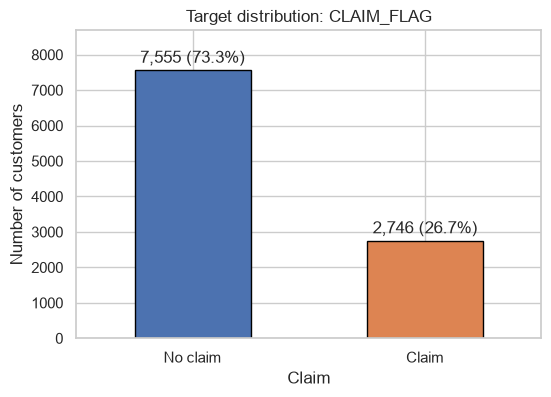

Claim
No claim    7555
Claim       2746
Name: count, dtype: int64

In [ ]:
counts = plot_df["Claim"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
counts.plot(kind="bar", color=[CLASS_COLORS[k] for k in counts.index], edgecolor="black", rot=0, ax=ax)


labels = [f"{v:,} ({v / counts.sum():.1%})" for v in counts]
ax.bar_label(ax.containers[0], labels=labels, padding=3)

ax.set_title("Target distribution: CLAIM_FLAG")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.15)

eda_figures["01_target_distribution"] = fig
plt.show()


**This figure shows** the number of customers who did and did not file a claim after cleaning, with the percentage on each bar. **We use it** to see the class balance of the target, which decides how we split the data and which metrics we use.

**Interpretation:** the classes are imbalanced: 7,555 customers (73.3%) did not claim and 2,746 (26.7%) did. A model that always predicts "no claim" would already reach 73% accuracy, so we use a stratified split and judge models mainly on ROC-AUC and F1, not accuracy.

### 4.2 Missing values

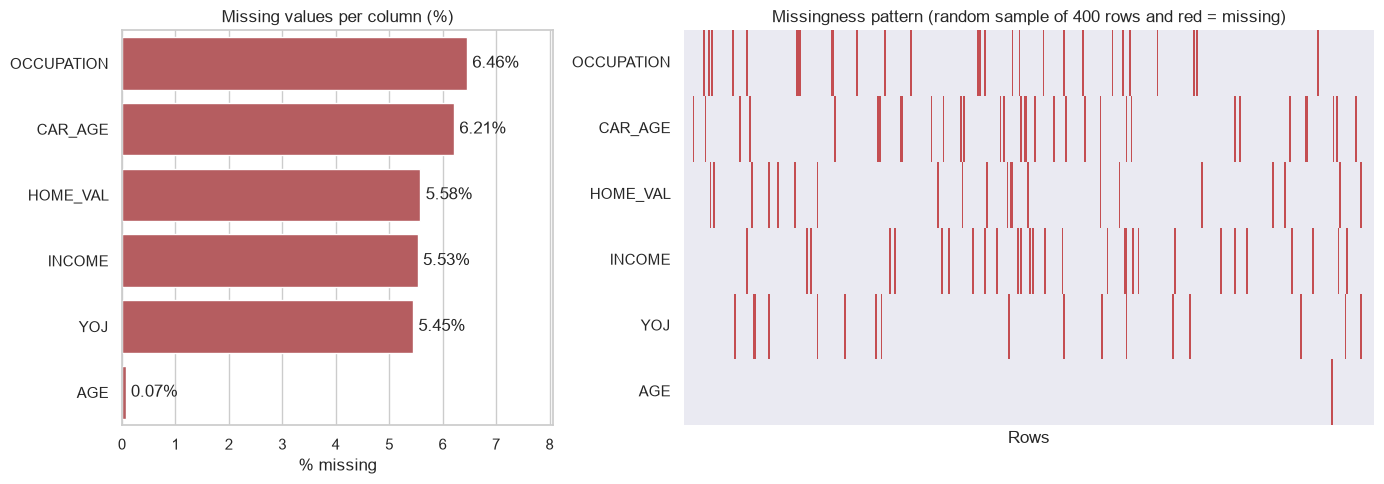

Correlation between missingness indicators:


,OCCUPATION,CAR_AGE,HOME_VAL,INCOME,YOJ,AGE
OCCUPATION,1.000,0.014,0.020,-0.005,-0.000,-0.007
CAR_AGE,0.014,1.000,0.009,0.012,-0.012,-0.007
HOME_VAL,0.020,0.009,1.000,0.015,-0.001,0.026
INCOME,-0.005,0.012,0.015,1.000,0.007,0.010
YOJ,-0.000,-0.012,-0.001,0.007,1.000,-0.006
AGE,-0.007,-0.007,0.026,0.010,-0.006,1.000


In [63]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: % missing per column
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=axes[0], color="#C44E52")
for i, v in enumerate(missing_pct.values):
    axes[0].text(v + 0.1, i, f"{v:.2f}%", va="center")
axes[0].set_title("Missing values per column (%)")
axes[0].set_xlabel("% missing"); axes[0].set_ylabel("")
axes[0].set_xlim(0, missing_pct.max() * 1.25)

# Right: where the missing values are (random sample of rows)
sample = df[missing_pct.index].isna().sample(400, random_state=RANDOM_STATE)
sns.heatmap(sample.T, cbar=False, cmap=["#EAEAF2", "#C44E52"], ax=axes[1], xticklabels=False)
axes[1].set_title("Missingness pattern (random sample of 400 rows and red = missing)")
axes[1].set_xlabel("Rows")

plt.tight_layout()
eda_figures["02_missing_values"] = fig
plt.show()

# Do columns tend to be missing together?
print("Correlation between missingness indicators:")
df[missing_pct.index].isna().corr().round(3)

**This figure shows** the % of missing values per column (left) and, for 400 random rows, exactly which cells are missing (right, red = missing). **We use it** to choose between dropping rows and imputing, and to see whether missing values appear together.

**Interpretation:** missingness is low (at most 6.46%, `OCCUPATION`) and scattered with no visible pattern. The correlations between the missingness indicators are all below 0.03, so a value missing in one column does not make another column more likely to be missing. Together with the similar claim rates for missing and present values (Section 2.5), this supports simple imputation (median for numeric, most frequent or "Unknown" for categorical) instead of dropping a quarter of the rows.

### 4.3 Numeric feature distributions

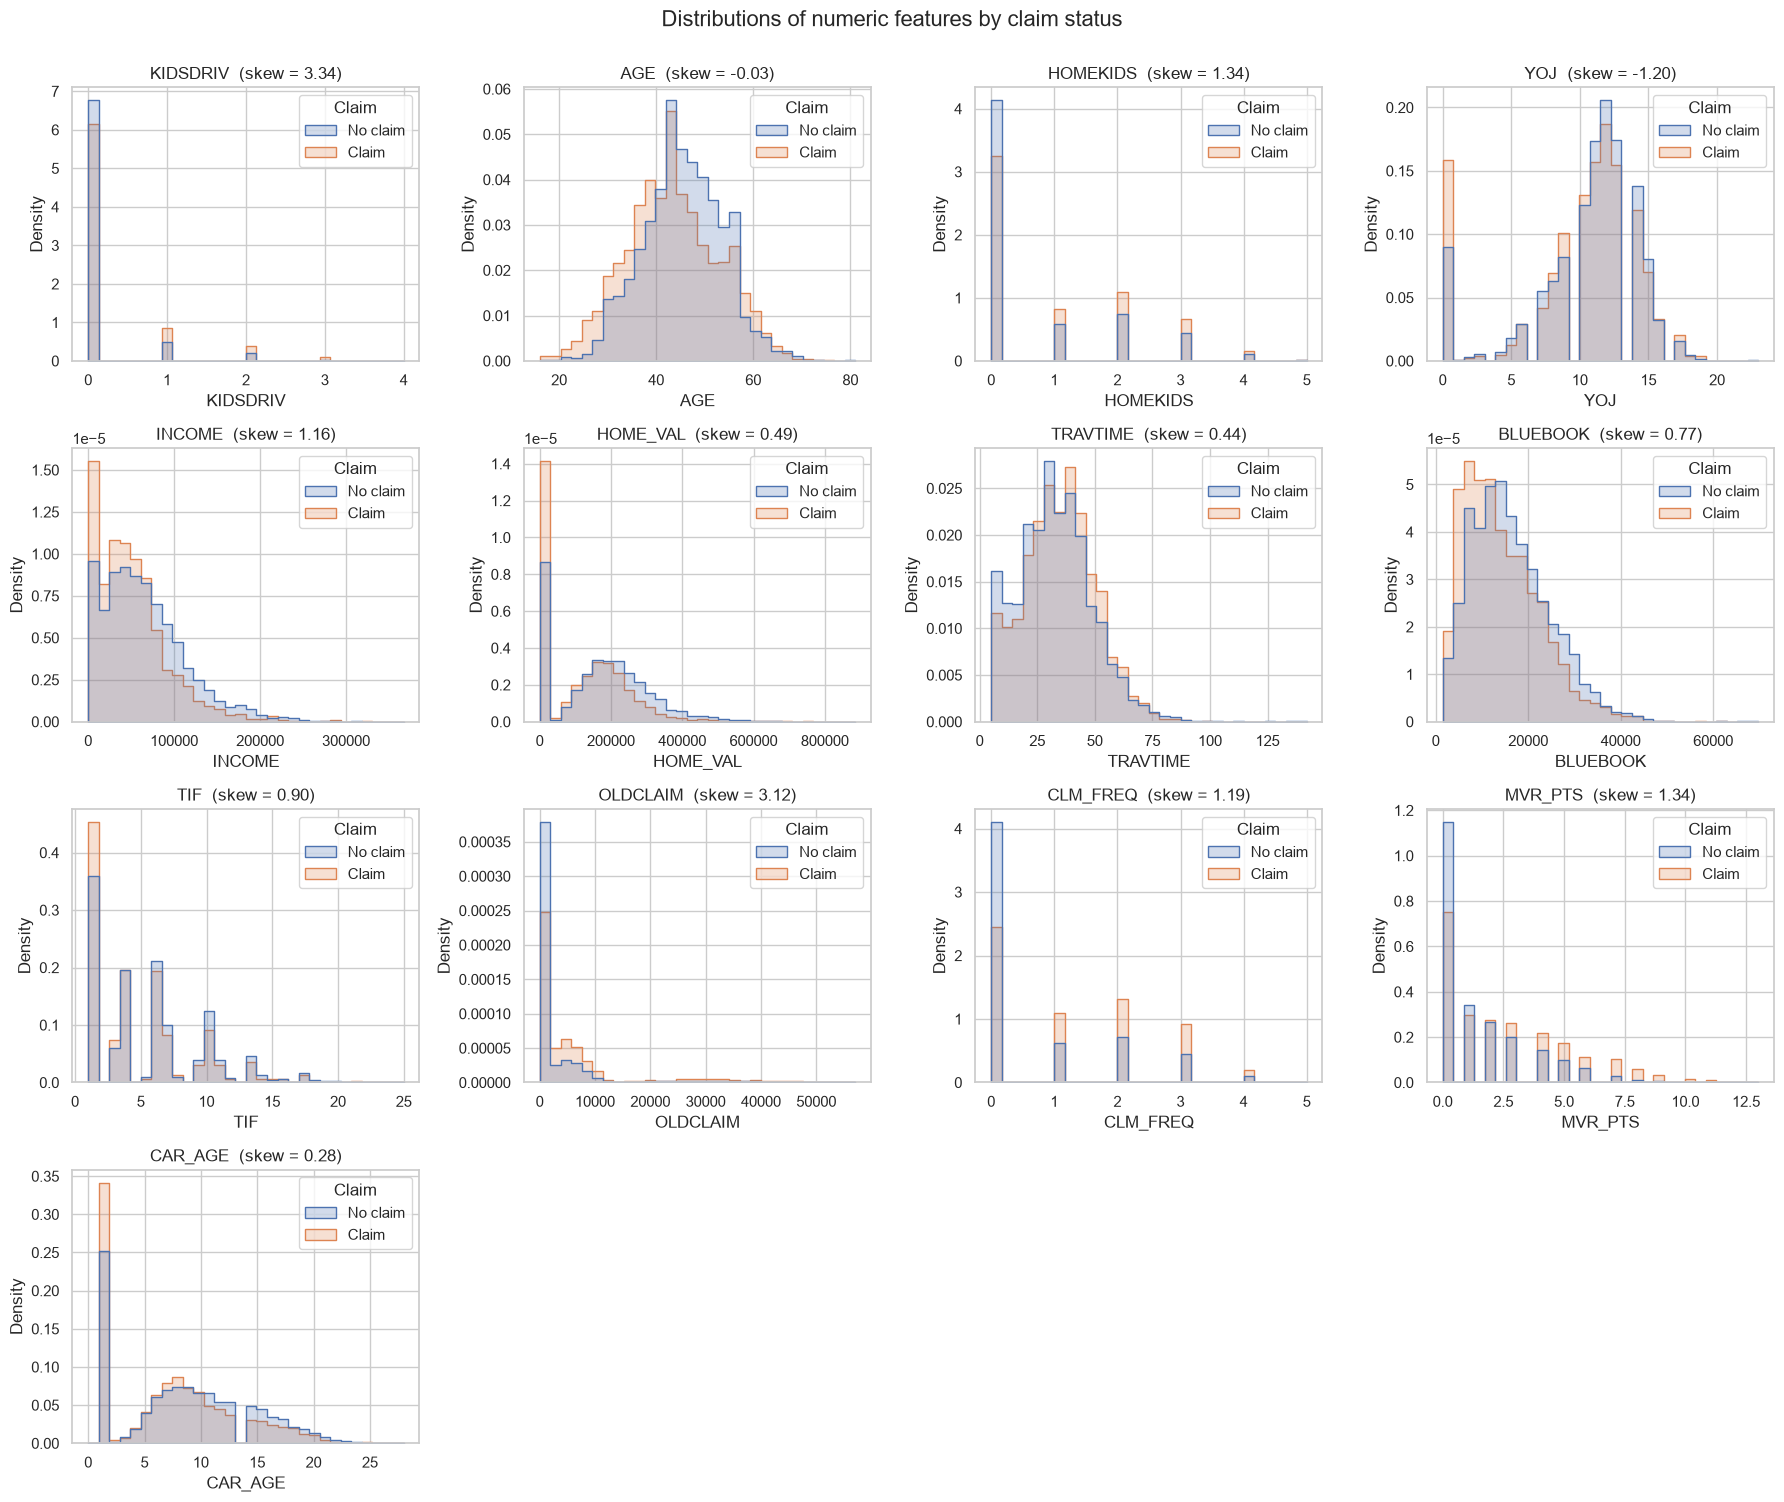

In [21]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
axes = axes.ravel()
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.histplot(data=plot_df, x=col, hue="Claim", stat="density", common_norm=False,
                 bins=30, element="step", palette=CLASS_COLORS, ax=ax)
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_ylabel("Density")
for ax in axes[len(NUMERIC_FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Distributions of numeric features by claim status", fontsize=16, y=1.0)
plt.tight_layout()
eda_figures["03_numeric_distributions"] = fig
plt.show()

**This figure shows** the distribution of each numeric feature, separately for claimants (orange) and non-claimants (blue). Densities are used so the two classes are comparable despite their different sizes, and the skewness is shown in each title. **We use it** to see the shape of each feature and which values are more common among claimants.

**Interpretation:** claimants are more common at `INCOME = 0`, `HOME_VAL = 0` (non-homeowners) and `YOJ = 0`, and at higher `CLM_FREQ`, `OLDCLAIM` and `MVR_PTS`. So past claims, traffic violations and lower financial stability go with claiming. Several features are strongly right-skewed or mostly zeros (`KIDSDRIV` skew 3.34, `OLDCLAIM` 3.12) and the features are on very different scales, so scaling is needed for KNN, SVM and Logistic Regression.

### 4.4 Boxplots by class

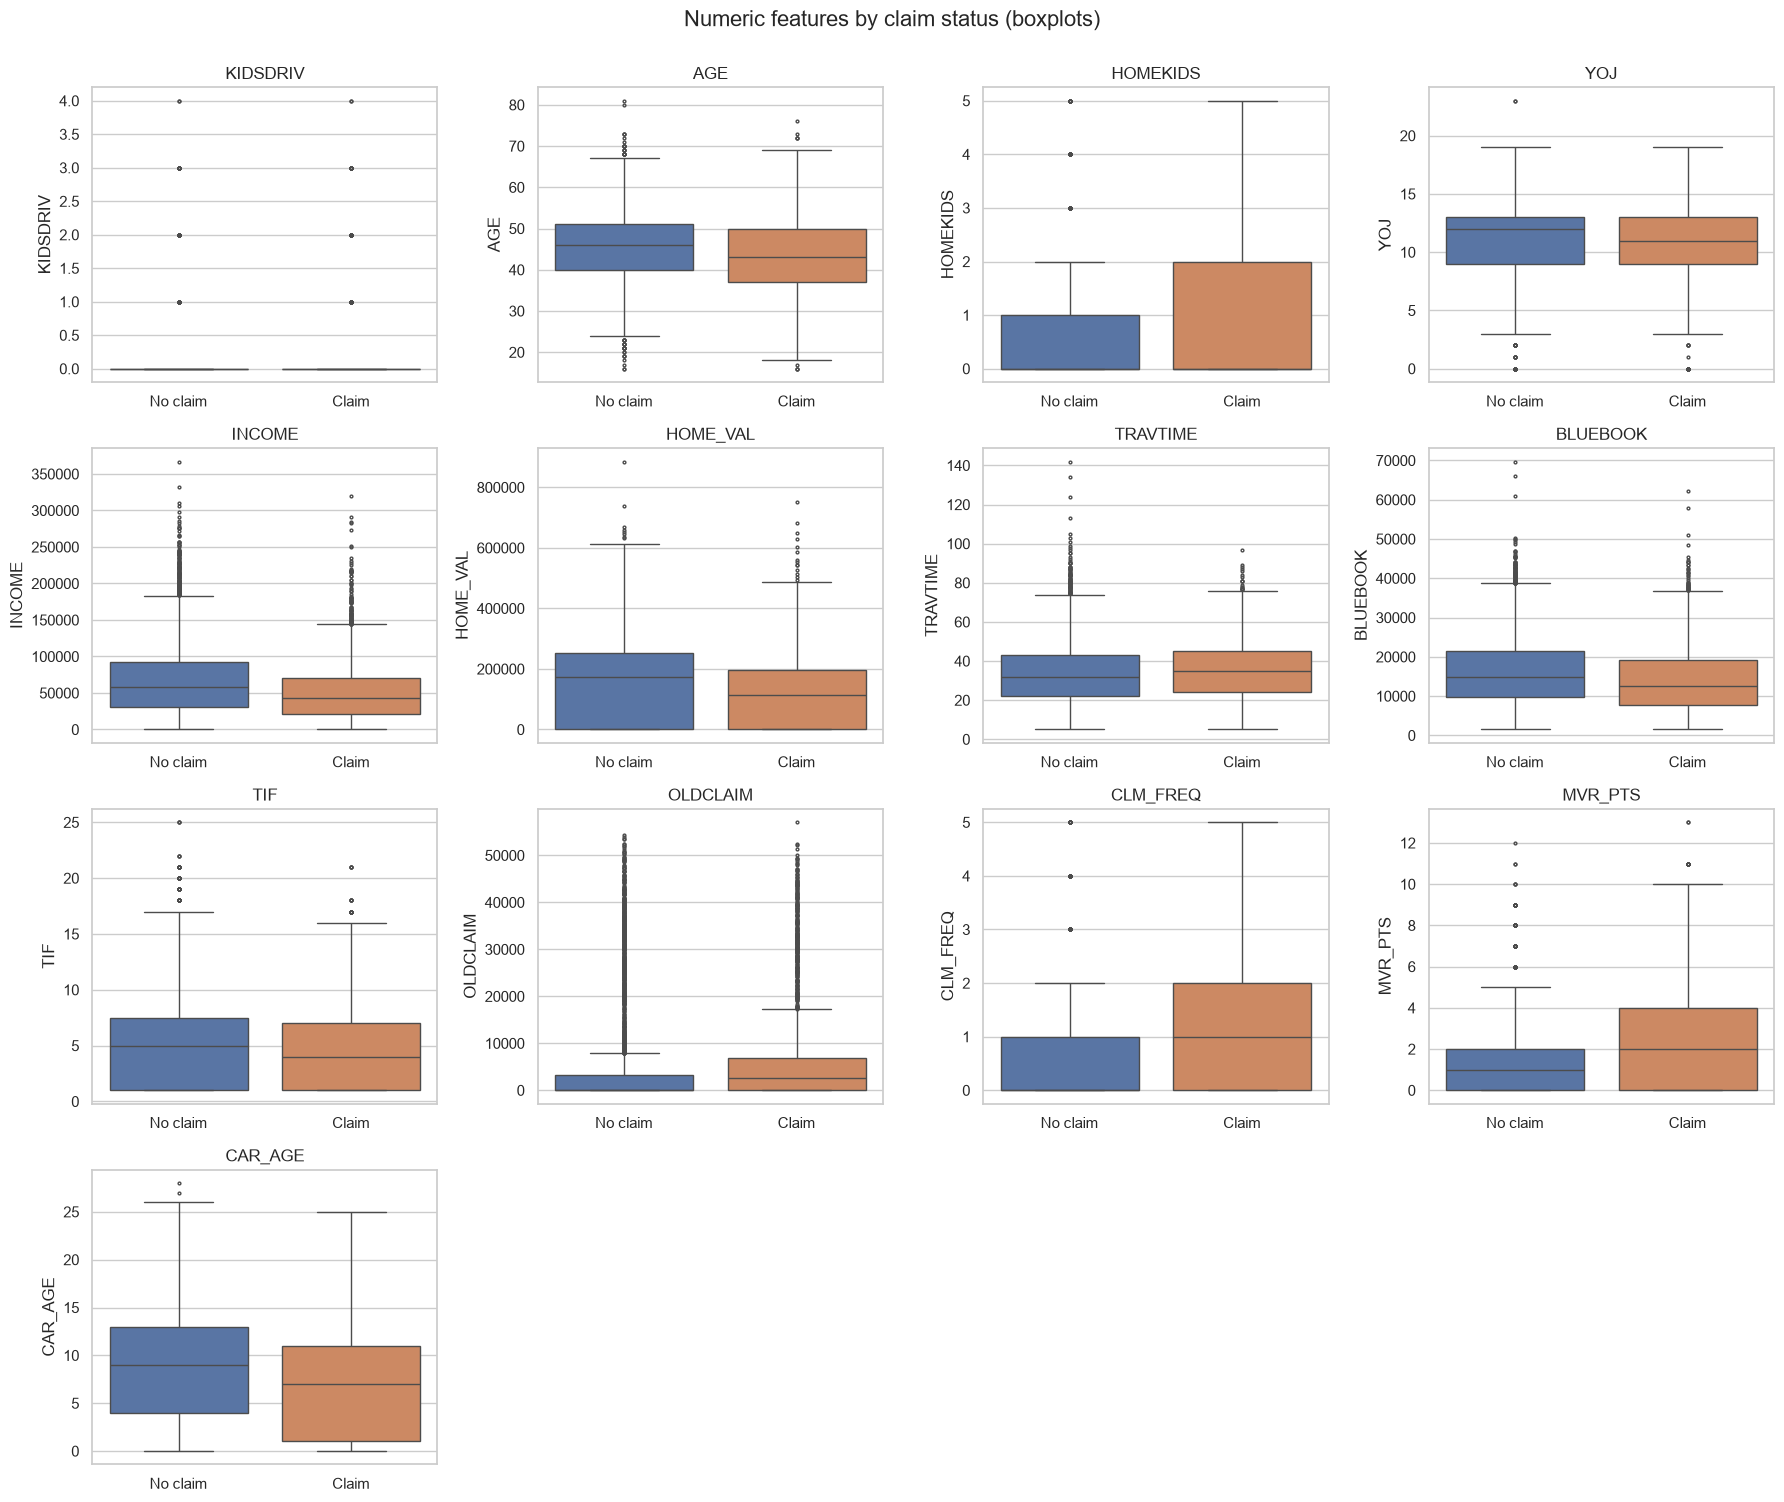

,median_no_claim,median_claim
KIDSDRIV,0.0,0.0
AGE,46.0,43.0
HOMEKIDS,0.0,0.0
YOJ,12.0,11.0
INCOME,58081.0,43663.5
HOME_VAL,174376.5,113151.5
TRAVTIME,32.0,35.0
BLUEBOOK,14920.0,12610.0
TIF,5.0,4.0
OLDCLAIM,0.0,2601.5


In [22]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
axes = axes.ravel()
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=plot_df, x="Claim", y=col, hue="Claim", order=["No claim", "Claim"],
                palette=CLASS_COLORS, legend=False, ax=ax, fliersize=2)
    ax.set_title(col); ax.set_xlabel("")
for ax in axes[len(NUMERIC_FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Numeric features by claim status (boxplots)", fontsize=16, y=1.0)
plt.tight_layout()
eda_figures["04_numeric_boxplots"] = fig
plt.show()

class_medians = df.groupby(TARGET)[NUMERIC_FEATURES].median().T
class_medians.columns = ["median_no_claim", "median_claim"]
class_medians

**This figure shows** boxplots of each numeric feature for the two classes (median, middle 50% of values and outlier points), and the table lists the median per class. **We use it** to compare the typical value of each feature between claimants and non-claimants, and to see the outliers found in Section 2.7.

**Interpretation:** claimants have a lower median income ($43,664 vs $58,081), home value ($113,152 vs $174,377) and car age (7 vs 9 years), and more traffic-violation points (2 vs 1) and past claims (1 vs 0). However, the boxes overlap heavily for every feature, so no single feature separates the classes on its own and the model must combine many features. The outlier points are real values (Section 2.7), so they are kept.

### 4.5 Claim rate by category

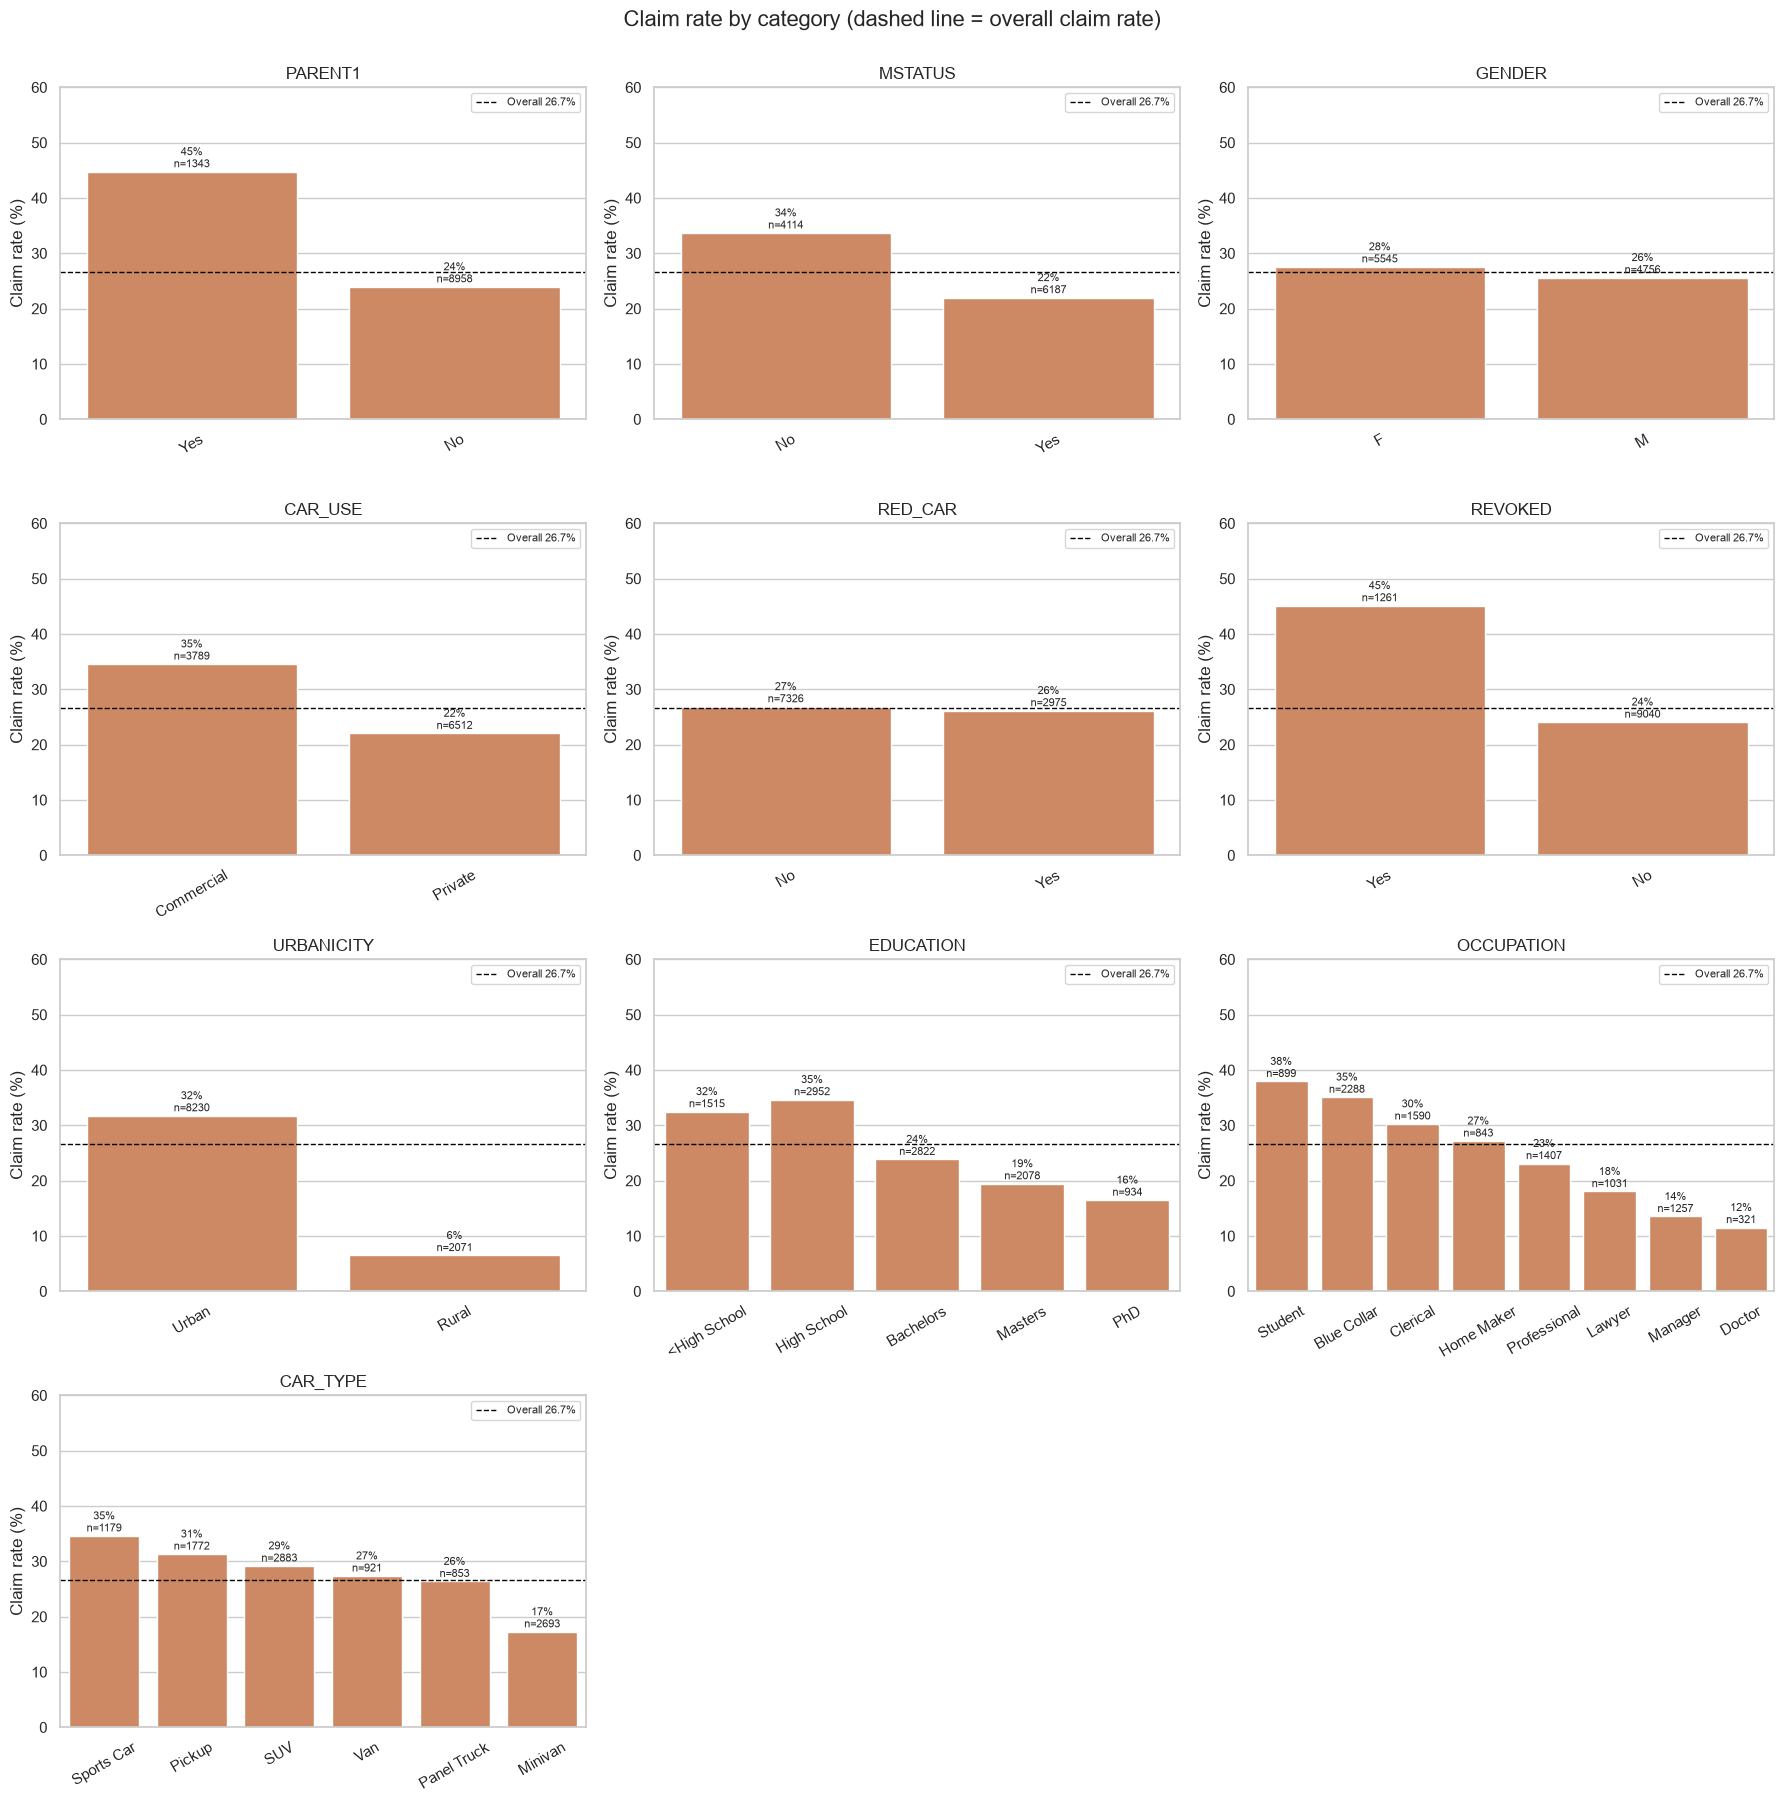

,feature,category,n,claim_rate_%
0,PARENT1,Yes,1343,44.8
1,PARENT1,No,8958,23.9
2,MSTATUS,No,4114,33.7
3,MSTATUS,Yes,6187,22.0
4,GENDER,F,5545,27.6
5,GENDER,M,4756,25.6
6,CAR_USE,Commercial,3789,34.6
7,CAR_USE,Private,6512,22.1
8,RED_CAR,No,7326,26.9
9,RED_CAR,Yes,2975,26.2


In [23]:
fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.ravel()
rate_rows = []
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    stats = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    if col != "EDUCATION":                      # keep EDUCATION in its natural order
        stats = stats.sort_values("mean", ascending=False)
    labels = stats.index.astype(str)
    sns.barplot(x=labels, y=stats["mean"] * 100, order=labels, color="#DD8452", ax=ax)
    ax.axhline(overall_rate * 100, color="black", ls="--", lw=1, label=f"Overall {overall_rate:.1%}")
    for i, (r, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(i, r * 100 + 0.8, f"{r:.0%}\nn={n}", ha="center", fontsize=8)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("Claim rate (%)"); ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper right", fontsize=8)
    for cat, (r, n) in stats.iterrows():
        rate_rows.append((col, cat, int(n), round(r * 100, 1)))
for ax in axes[len(CATEGORICAL_FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Claim rate by category (dashed line = overall claim rate)", fontsize=16, y=1.0)
plt.tight_layout()
eda_figures["05_categorical_claim_rates"] = fig
plt.show()

claim_rate_table = pd.DataFrame(rate_rows, columns=["feature", "category", "n", "claim_rate_%"])
claim_rate_table

**This figure shows** the claim rate of every category of each categorical feature, with the group size `n` above each bar. The dashed line is the overall claim rate (26.7%), so bars above it are higher-risk groups. **We use it** to find which categorical features are related to claiming, and to check whether `EDUCATION` has a natural order.

**Interpretation:**
- **Strongest effects:** urban customers claim about 5 times as often as rural ones (31.7% vs 6.5%). Single parents (44.8% vs 23.9%) and drivers with a revoked licence (45.1% vs 24.1%) claim almost twice as often.
- Commercial use (34.6% vs 22.1%) and being unmarried (33.7% vs 22.0%) also raise the risk.
- **Education:** the claim rate falls with education, from High School (34.7%) to PhD (16.5%). This supports treating it as an *ordinal* feature.
- **Occupation:** ranges from Students (37.9%) down to Doctors (11.5%). **Car type:** Sports Cars are highest (34.6%) and Minivans lowest (17.3%).
- **Red-car myth:** red and non-red cars have the same claim rate (26.2% vs 26.9%), so the belief is **not supported** by the data. Gender also makes little difference (27.6% vs 25.6%).

### 4.6 Correlation analysis

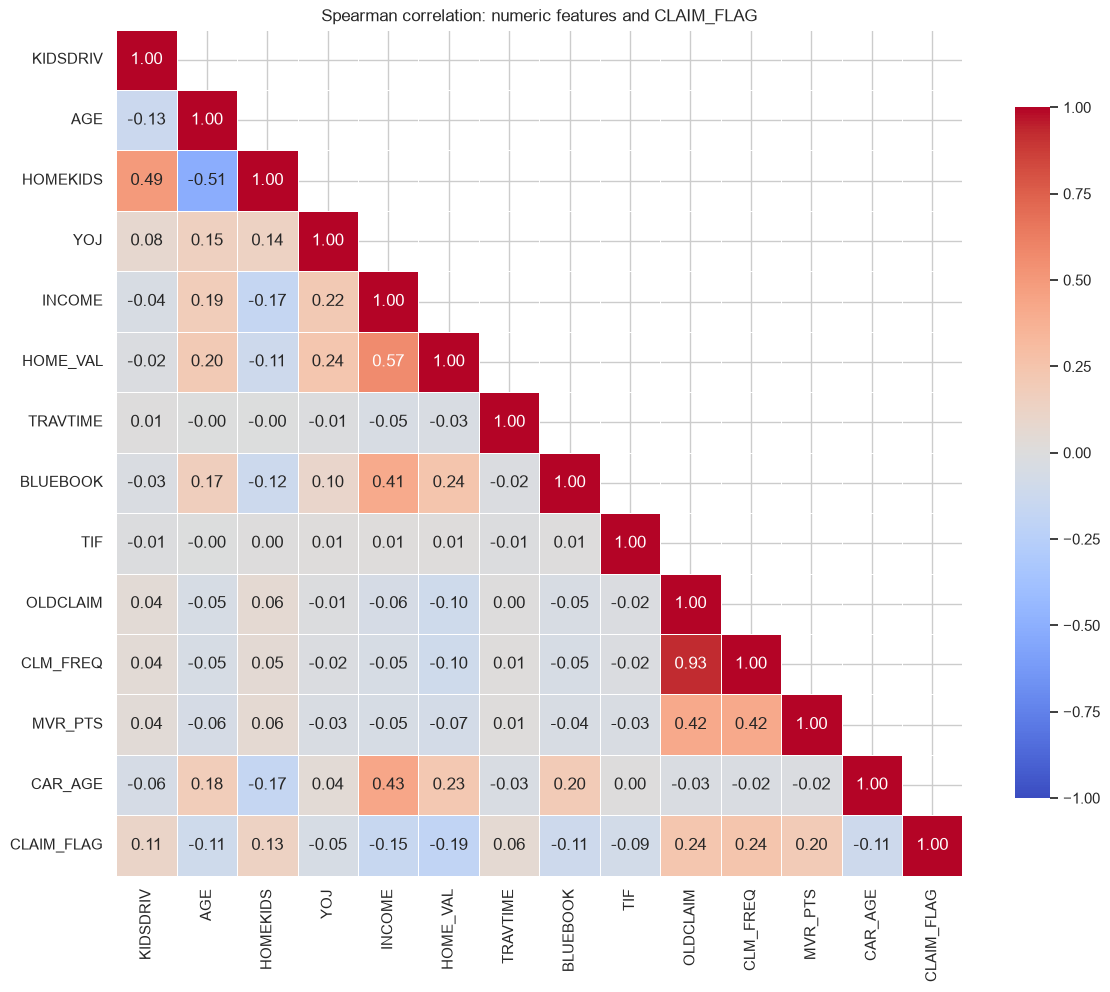

Correlation with CLAIM_FLAG (sorted by strength):
CLM_FREQ    0.244
OLDCLAIM    0.240
MVR_PTS     0.199
HOME_VAL   -0.189
INCOME     -0.150
HOMEKIDS    0.133
BLUEBOOK   -0.112
KIDSDRIV    0.111
CAR_AGE    -0.110
AGE        -0.107
TIF        -0.086
TRAVTIME    0.061
YOJ        -0.052
Name: CLAIM_FLAG, dtype: float64

Top correlated feature pairs:
OLDCLAIM  CLM_FREQ    0.926
INCOME    HOME_VAL    0.566
AGE       HOMEKIDS   -0.515
KIDSDRIV  HOMEKIDS    0.492
INCOME    CAR_AGE     0.430
CLM_FREQ  MVR_PTS     0.418
dtype: float64


In [24]:
corr = df[NUMERIC_FEATURES + [TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation: numeric features and CLAIM_FLAG")
plt.tight_layout()
eda_figures["07_correlation_heatmap"] = fig
plt.show()

print("Correlation with CLAIM_FLAG (sorted by strength):")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

# Most correlated feature pairs (possible redundancy / multicollinearity)
pairs = (corr.drop(index=TARGET, columns=TARGET)
             .where(np.triu(np.ones((len(NUMERIC_FEATURES),) * 2, dtype=bool), k=1))
             .stack().sort_values(key=abs, ascending=False))
print("\nTop correlated feature pairs:")
print(pairs.head(6).round(3))

**This figure shows** the Spearman correlation between every pair of numeric features and the target (red = positive, blue = negative). Spearman uses ranks, so it is robust to the skew and outliers seen above and captures any monotonic relationship. **We use it** to measure how strongly each feature is linked to claiming and to find redundant feature pairs.

**Interpretation:** every feature is only weakly correlated with the target. The strongest are `CLM_FREQ` (0.244), `OLDCLAIM` (0.240), `MVR_PTS` (0.199), `HOME_VAL` (-0.189) and `INCOME` (-0.150), which again shows that prediction needs many features combined. Among the features, `OLDCLAIM` and `CLM_FREQ` are almost duplicates (0.93), and `INCOME` and `HOME_VAL` (0.57) and `AGE` and `HOMEKIDS` (-0.51) are moderately correlated. This redundancy makes the coefficients of linear models harder to read and is something feature selection (Section 7) should check.

### 4.7 EDA conclusions and implications for modelling
1. **Imbalanced target (27% claims):** use a stratified split, judge models on ROC-AUC (main metric) and F1 rather than accuracy, and try `class_weight="balanced"`.
2. **No single strong predictor:** all correlations with the target are weak (|rho| <= 0.25) and the class distributions overlap, so the models must combine many features. Non-linear models (Decision Tree, SVM, Gradient Boosting) can also use interactions between them.
3. **Most informative signals:** urban living, past claims, traffic-violation points, revoked licence, single parenthood, commercial car use, lower income, home value and education.
4. **Weak or redundant features:** `RED_CAR` (no effect), `GENDER` (very small effect) and the `OLDCLAIM`/`CLM_FREQ` pair (rho = 0.93) are checked in feature selection (Section 7).
5. **Skewed numeric features on different scales:** scaling is needed for distance- and gradient-based models (KNN, SVM, Logistic Regression), while tree-based models are not affected.
6. **Missing values are scattered and unrelated to the target:** median / most-frequent imputation inside the pipeline is appropriate.

### 4.8 Logging the EDA figures
The six figures above are logged to MLflow in one run, so they can be viewed in the MLflow UI next to the model results.

In [25]:
# log all EDA figures to MLflow in one run
with mlflow.start_run(run_name="eda - figures"):
    mlflow.set_tag("stage", "eda")
    for name, figure in eda_figures.items():
        mlflow.log_figure(figure, "eda/" + name + ".png")
print(len(eda_figures), "EDA figures logged to MLflow")

6 EDA figures logged to MLflow


## 5. Preprocessing
### 5.1 Checking zero values
A zero can be a real value (no children, no past claims) or a disguised missing value. We check the suspicious zeros against related features.

In [26]:
# HOMEKIDS: does any single parent have 0 children at home?
print(pd.crosstab(df["HOMEKIDS"] == 0, df["PARENT1"],
                  rownames=["HOMEKIDS = 0"], colnames=["Single parent"]), "\n")

# INCOME and YOJ: do the zeros occur together? (only rows where both are known)
both_known = df.dropna(subset=["INCOME", "YOJ"])
print(pd.crosstab(both_known["INCOME"] == 0, both_known["YOJ"] == 0,
                  rownames=["INCOME = 0"], colnames=["YOJ = 0"]), "\n")
print("Occupations with INCOME = 0:")
print(df.loc[df["INCOME"] == 0, "OCCUPATION"].value_counts(), "\n")

# HOME_VAL: is 0 the renter profile? (share of zeros among unmarried vs married)
print(pd.crosstab(df["HOME_VAL"] == 0, df["MSTATUS"], normalize="columns",
                  rownames=["HOME_VAL = 0"], colnames=["Married"]).round(3), "\n")


Single parent    No   Yes
HOMEKIDS = 0             
False          2265  1343
True           6693     0 

YOJ = 0     False  True 
INCOME = 0              
False        8451      2
True            0    752 

Occupations with INCOME = 0:
OCCUPATION
Student         402
Home Maker      378
Lawyer            8
Doctor            6
Professional      2
Manager           1
Blue Collar       0
Clerical          0
Name: count, dtype: int64 

Married          No    Yes
HOME_VAL = 0              
False         0.402  0.928
True          0.598  0.072 



**Findings: all zeros are real values, not hidden missing data.** The dataset already marks unknown values as NaN in the same columns (for example 575 in `HOME_VAL`, Section 2.2), so a 0 is a deliberate value:
- **KIDSDRIV / HOMEKIDS:** 0 = no children who drive / at home. Every single parent has `HOMEKIDS > 0`, so the data is consistent.
- **YOJ / INCOME:** 0 = not currently working. Where both are known, the two zeros occur together (752 rows, only 2 exceptions), and almost all of them are Students (402) and Home Makers (378).
- **HOME_VAL:** 0 = does not own a home. Zeros are common among unmarried customers (59.8%) and rare among married ones (7.2%), which matches a renter profile.
- **OLDCLAIM / CLM_FREQ:** 0 = no claims in the past 5 years. The two columns are zero in exactly the same rows (Section 3.5).
- **MVR_PTS:** 0 = clean driving record. **CAR_AGE = 0** (4 cars) = brand-new car.

Replacing these zeros with an imputed median would destroy real information: for example, `INCOME = 0` and `HOME_VAL = 0` are more common among claimants (Section 4.3), so they are useful signals for the models.

### 5.2 Train/test split
The features `X` and the target `y` are separated, then split 80% / 20% with `train_test_split`. `stratify=y` keeps the same claim ratio (about 26.7%) in both sets. The test set is set aside and only used for the final evaluation.

In [27]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=TARGET)      # the 23 features
y = df[TARGET]                   # the target (0/1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,               # 20% test, 80% train
    stratify=y,                  # same class ratio in both sets
    random_state=RANDOM_STATE,   # same split every time we run
)

print("Train:", X_train.shape, "| Test:", X_test.shape, "\n")
pd.DataFrame({
    "train_%": (y_train.value_counts(normalize=True) * 100).round(2),
    "test_%":  (y_test.value_counts(normalize=True) * 100).round(2),
})

Train: (8240, 23) | Test: (2061, 23) 



,train_%,test_%
CLAIM_FLAG,,
0,73.34,73.36
1,26.66,26.64


### 5.3 Preprocessing pipeline
Each feature group gets its own steps, chained with `Pipeline`, and `ColumnTransformer` applies each group's pipeline to its own columns:

| Group | Missing values | Encoding / scaling | Why |
|---|---|---|---|
| Numeric (13) | **Median** | `StandardScaler` | median is robust to the skew and outliers seen in EDA; scaling is needed by KNN, SVM and Logistic Regression |
| Binary (7) | Most frequent | `OneHotEncoder(drop="if_binary")` → one 0/1 column | two categories need only one column |
| Ordinal (1): `EDUCATION` | Most frequent | `OrdinalEncoder` in the order `<High School` to `PhD`, then scaled | keeps the natural order (the claim rate falls with education, Section 4.5) |
| Nominal (2): `OCCUPATION`, `CAR_TYPE` | Constant **"Unknown"** | `OneHotEncoder` → one column per category | no order exists, so each category gets its own column |

**Why "Unknown" for `OCCUPATION`:** filling with the most frequent value would label the 6.5% of missing rows as "Blue Collar", a high-risk group (35.1% claim rate). But the missing rows have a claim rate of 26.2%, close to the average. A separate "Unknown" category keeps them distinct instead of distorting the Blue Collar group.

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])

binary_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="if_binary", sparse_output=False)),
])

ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[EDUCATION_ORDER])),
    ("scaler",  StandardScaler()),
])

nominal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC_FEATURES),
    ("bin", binary_pipe,  BINARY_FEATURES),
    ("ord", ordinal_pipe, ORDINAL_FEATURES),
    ("nom", nominal_pipe, NOMINAL_FEATURES),
])
preprocessor.set_output(transform="pandas")   # output a DataFrame with column names
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

### 5.4 Fitting the preprocessor (training data only)
`fit_transform` on the training set learns the medians, most-frequent values, categories, means and standard deviations, and transforms the training data. `transform` on the test set reuses those learned values without learning anything new, which prevents data leakage. We then check that no missing values remain and that the numeric columns have mean ≈ 0 and standard deviation ≈ 1.

In [29]:
X_train_prep = preprocessor.fit_transform(X_train)   # learn from train + transform train
X_test_prep  = preprocessor.transform(X_test)        # only transform test

print("Train after preprocessing:", X_train_prep.shape)
print("Test  after preprocessing:", X_test_prep.shape)
print("Missing values left -> train:", X_train_prep.isna().sum().sum(),
      "| test:", X_test_prep.isna().sum().sum(), "\n")

# What the imputer learned for each numeric column (the training medians)
learned_medians = pd.Series(
    preprocessor.named_transformers_["num"].named_steps["imputer"].statistics_,
    index=NUMERIC_FEATURES,
)
print("Training medians used for imputation:")
print(learned_medians, "\n")

print("Numeric columns after scaling (should be mean 0, std 1):")
print(X_train_prep.filter(like="num__").describe().loc[["mean", "std"]].round(2), "\n")

X_train_prep.head()

Train after preprocessing: (8240, 36)
Test  after preprocessing: (2061, 36)
Missing values left -> train: 0 | test: 0 

Training medians used for imputation:
KIDSDRIV         0.0
AGE             45.0
HOMEKIDS         0.0
YOJ             11.0
INCOME       53406.5
HOME_VAL    160875.5
TRAVTIME        33.0
BLUEBOOK     14430.0
TIF              4.0
OLDCLAIM         0.0
CLM_FREQ         0.0
MVR_PTS          1.0
CAR_AGE          8.0
dtype: float64 

Numeric columns after scaling (should be mean 0, std 1):
      num__KIDSDRIV  num__AGE  num__HOMEKIDS  num__YOJ  num__INCOME  num__HOME_VAL  num__TRAVTIME  num__BLUEBOOK  num__TIF  num__OLDCLAIM  num__CLM_FREQ  num__MVR_PTS  num__CAR_AGE
mean            0.0      -0.0           -0.0      -0.0          0.0           -0.0            0.0            0.0      -0.0            0.0            0.0          -0.0          -0.0
std             1.0       1.0            1.0       1.0          1.0            1.0            1.0            1.0       1.0           

,num__KIDSDRIV,num__AGE,num__HOMEKIDS,num__YOJ,num__INCOME,num__HOME_VAL,num__TRAVTIME,num__BLUEBOOK,num__TIF,num__OLDCLAIM,num__CLM_FREQ,num__MVR_PTS,num__CAR_AGE,bin__PARENT1_Yes,bin__MSTATUS_Yes,bin__GENDER_M,bin__CAR_USE_Private,bin__RED_CAR_Yes,bin__REVOKED_Yes,bin__URBANICITY_Urban,ord__EDUCATION,nom__OCCUPATION_Blue Collar,nom__OCCUPATION_Clerical,nom__OCCUPATION_Doctor,nom__OCCUPATION_Home Maker,nom__OCCUPATION_Lawyer,nom__OCCUPATION_Manager,nom__OCCUPATION_Professional,nom__OCCUPATION_Student,nom__OCCUPATION_Unknown,nom__CAR_TYPE_Minivan,nom__CAR_TYPE_Panel Truck,nom__CAR_TYPE_Pickup,nom__CAR_TYPE_SUV,nom__CAR_TYPE_Sports Car,nom__CAR_TYPE_Van
9136,-0.335183,1.180831,-0.643650,0.625912,-0.608767,0.347128,-0.409465,-1.293378,1.361128,-0.461324,-0.695791,0.594723,-1.327968,0.0,1.0,1.0,0.0,1.0,0.0,1.0,-1.521881,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2145,3.618870,-0.564740,2.035876,0.875079,-0.161555,0.111909,-0.029675,1.007251,0.152123,-0.461324,-0.695791,-0.791693,1.230090,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.174129,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5839,-0.335183,-0.681112,0.249525,1.622580,-1.018931,-0.449336,0.096922,-0.236301,0.152123,-0.461324,-0.695791,1.056862,-1.327968,0.0,1.0,0.0,1.0,0.0,0.0,0.0,-1.521881,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
532,3.618870,-0.448369,2.035876,-0.121590,-0.783456,-1.234525,-0.472763,-0.937060,-1.056881,-0.340153,2.779474,0.132584,0.316498,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.174129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2948,-0.335183,0.715345,-0.643650,0.376744,0.894085,0.948351,0.919800,-0.271932,-0.331478,-0.461324,-0.695791,-0.791693,1.595527,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.870140,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


**Result:** the 23 original features become **36 model-ready columns**: 13 scaled numeric, 7 binary 0/1, 1 scaled ordinal, and 15 one-hot columns (9 for `OCCUPATION` including "Unknown", 6 for `CAR_TYPE`). No missing values remain, and the numeric columns have mean 0 and standard deviation 1.
**How this is used next:** this same `preprocessor` will be placed *inside* each model's pipeline (`Pipeline([("prep", preprocessor), ("model", ...)])`). That way, during cross-validation it is re-fitted on each training fold only, so tuning never sees the validation fold. `X_train_prep` here is only for inspection.

## 6. Baseline Models
We train 5 models with their **default settings**, plus a Dummy model, and compare them with 5-fold stratified cross-validation on the **training set only**. The test set is not used until Section 9.

| Model | Family | How it decides |
|---|---|---|
| Dummy | Reference | always predicts the most common class (no claim), any real model must beat it |
| Logistic Regression | Linear | weighted sum of the features turned into a probability by the sigmoid function  |
| Decision Tree | Tree | a chain of yes/no questions on the features  |
| KNN | Instance based | majority vote of the k most similar customers  |
| SVM (RBF kernel) | Margin based | the boundary with the widest gap between the classes, the RBF kernel lets it bend |
| Gradient Boosting | Ensemble (boosting) | many small trees added one after another, each one fixes the errors of the previous ones |

**Metrics:** ROC-AUC is the main metric because it measures how well a model ranks claimants above non-claimants, without depending on a threshold. F1 is the second metric because it balances precision and recall on the claim class. Accuracy is not used for ranking because predicting "no claim" for everyone already gives 73%.

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

warnings.filterwarnings("ignore")   # hides the Dummy "precision is 0" warning and similar ones

# same 5 folds for every model, each fold keeps the 73/27 class ratio
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

baseline_models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

for name, model in baseline_models.items():
    print(name, "->", model)

Dummy -> DummyClassifier(strategy='most_frequent')
Logistic Regression -> LogisticRegression(max_iter=1000, random_state=42)
Decision Tree -> DecisionTreeClassifier(random_state=42)
KNN -> KNeighborsClassifier()
SVM -> SVC(random_state=42)
Gradient Boosting -> GradientBoostingClassifier(random_state=42)


### 6.1 Cross-validating the baseline models
Each model is placed in a pipeline after the preprocessor from Section 5, so imputation, encoding and scaling are learned again inside every fold. Each model gets one MLflow run with its parameters and its mean CV scores. The training F1 is also kept to check overfitting later.

In [31]:
baseline_results = {}

for name, model in baseline_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING,
                            return_train_score=True, n_jobs=1)

    result = {}
    for metric in SCORING:
        result[metric] = scores["test_" + metric].mean()   # mean over the 5 validation folds
    result["train_f1"] = scores["train_f1"].mean()
    baseline_results[name] = result

    with mlflow.start_run(run_name="baseline - " + name):
        mlflow.set_tag("stage", "baseline")
        mlflow.set_tag("model", name)
        mlflow.log_params(model.get_params())
        for metric, value in result.items():
            mlflow.log_metric("cv_" + metric, value)

    print(name, "| ROC-AUC:", round(result["roc_auc"], 3), "| F1:", round(result["f1"], 3))

baseline_df = pd.DataFrame(baseline_results).T.sort_values("roc_auc", ascending=False).round(3)
baseline_df

Dummy | ROC-AUC: 0.5 | F1: 0.0
Logistic Regression | ROC-AUC: 0.81 | F1: 0.509
Decision Tree | ROC-AUC: 0.615 | F1: 0.438
KNN | ROC-AUC: 0.704 | F1: 0.404
SVM | ROC-AUC: 0.794 | F1: 0.474
Gradient Boosting | ROC-AUC: 0.823 | F1: 0.523


,accuracy,precision,recall,f1,roc_auc,train_f1
Gradient Boosting,0.795,0.691,0.422,0.523,0.823,0.596
Logistic Regression,0.785,0.652,0.418,0.509,0.810,0.516
SVM,0.786,0.686,0.363,0.474,0.794,0.602
KNN,0.744,0.535,0.325,0.404,0.704,0.589
Decision Tree,0.693,0.428,0.448,0.438,0.615,1.000
Dummy,0.733,0.000,0.000,0.000,0.500,0.000


**Findings:** Gradient Boosting ranks claimants best (ROC-AUC 0.823), followed by Logistic Regression (0.810) and SVM (0.794). KNN (0.704) and the default Decision Tree (0.615) are clearly weaker. The Dummy reaches 73.3% accuracy without catching a single claim, and the Decision Tree's accuracy (69.3%) is even lower than that, which is why accuracy is not used to rank the models. At the default 0.5 threshold the models catch only 33% to 45% of the claimants (recall).

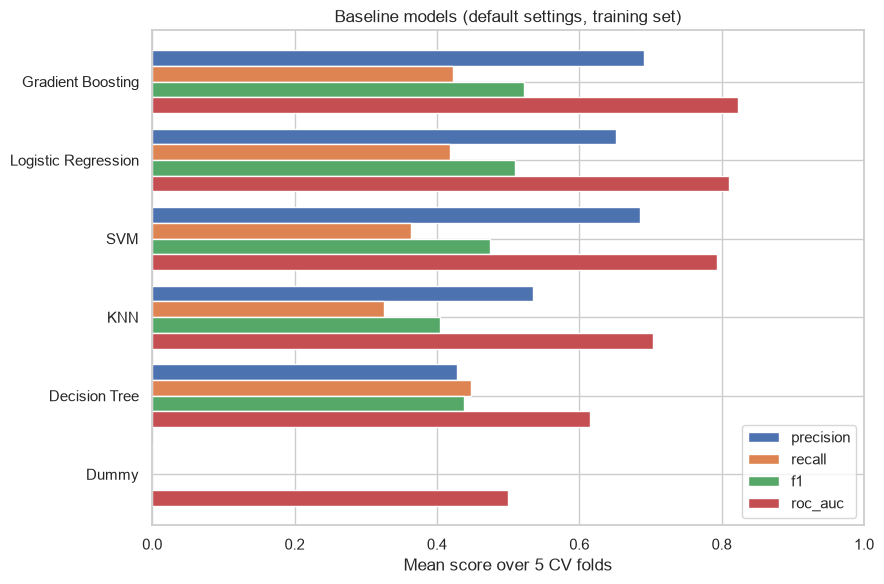

In [32]:
ax = baseline_df[["precision", "recall", "f1", "roc_auc"]].plot.barh(figsize=(9, 6), width=0.8)
ax.invert_yaxis()                    # best model on top
ax.set_xlim(0, 1)
ax.set_xlabel("Mean score over 5 CV folds")
ax.set_title("Baseline models (default settings, training set)")
ax.legend(loc="lower right")
plt.tight_layout()
fig = ax.get_figure()
plt.show()

with mlflow.start_run(run_name="baseline - comparison"):
    mlflow.set_tag("stage", "baseline")
    mlflow.log_figure(fig, "baseline/baseline_scores.png")
    mlflow.log_text(baseline_df.to_csv(), "baseline/baseline_results.csv")

**This figure shows** the mean 5-fold CV precision, recall, F1 and ROC-AUC of every baseline model, best ROC-AUC on top. **We use it** as the starting point that tuning (Section 8) must beat.

**Interpretation:** the simple Logistic Regression is only 0.013 ROC-AUC behind Gradient Boosting, so most of the signal is simple and additive. The better models have high precision (0.65 to 0.69) but low recall (0.36 to 0.42): they rarely predict a claim because only 27% of customers claim. This is the class imbalance problem that Section 8 deals with.

### 6.2 Overfitting check
We compare the F1 on the training folds with the F1 on the validation folds. A big gap means the model memorises the training data (overfitting). Low scores on both with no gap mean the model is too simple (underfitting).

In [33]:
overfit = pd.DataFrame({
    "train_f1": baseline_df["train_f1"],
    "validation_f1": baseline_df["f1"],
})
overfit["gap"] = overfit["train_f1"] - overfit["validation_f1"]
overfit.sort_values("gap", ascending=False)

,train_f1,validation_f1,gap
Decision Tree,1.000,0.438,0.562
KNN,0.589,0.404,0.185
SVM,0.602,0.474,0.128
Gradient Boosting,0.596,0.523,0.073
Logistic Regression,0.516,0.509,0.007
Dummy,0.000,0.000,0.000


**Findings:** the default Decision Tree memorises the training data (training F1 1.000 vs validation 0.438, gap 0.562), so it overfits badly. KNN (gap 0.185) and SVM (0.128) also overfit a little. Logistic Regression has almost no gap (0.007): it does not overfit, but its scores are limited by its simple linear form. Section 8 tunes the models to reduce these gaps.

## 7. Feature Selection
All feature selection is done on the **training set only**. We use three kinds of methods:
- **Filter methods** (variance threshold, mutual information): score each feature with a statistic, no model needed.
- **Wrapper methods** (SFS and SBS with mlxtend): try many feature subsets with a model and keep the best one.
- **Embedded method** (L1 regularisation): the model removes features by itself while training. It is shown in Section 8.5 with the tuned Logistic Regression.

### 7.1 Variance threshold
A column that has almost the same value for every customer cannot help separate the classes. `VarianceThreshold` removes columns with a variance below 0.01. It is applied to the preprocessed training data (`X_train_prep`, 36 columns).

In [34]:
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif

vt = VarianceThreshold(threshold=0.01)
vt.fit(X_train_prep)

variance_table = pd.DataFrame({"variance": vt.variances_, "selected": vt.get_support()},
                              index=X_train_prep.columns)
print("Columns removed:", (~vt.get_support()).sum())
variance_table.sort_values("variance").head()

Columns removed: 0


,variance,selected
nom__OCCUPATION_Doctor,0.030330,True
nom__OCCUPATION_Unknown,0.059548,True
nom__OCCUPATION_Home Maker,0.074598,True
nom__CAR_TYPE_Panel Truck,0.076928,True
nom__CAR_TYPE_Van,0.080144,True


**Findings:** no column is removed. The lowest variance is 0.030 for `OCCUPATION_Doctor` (about 3% of customers are doctors), which is still above 0.01. After scaling, every numeric column has variance 1, so no column is close to constant.

### 7.2 Mutual information
Mutual information measures how much knowing a feature tells us about `CLAIM_FLAG` (0 = nothing). It also catches non-linear relations. The one-hot columns of `OCCUPATION` and `CAR_TYPE` are added up so each original feature gets one score.

By default `mutual_info_classif` treats every column as continuous, which gives wrong values for counts, binary and one-hot columns. So only the 5 truly continuous columns (money and travel time) are marked as continuous.

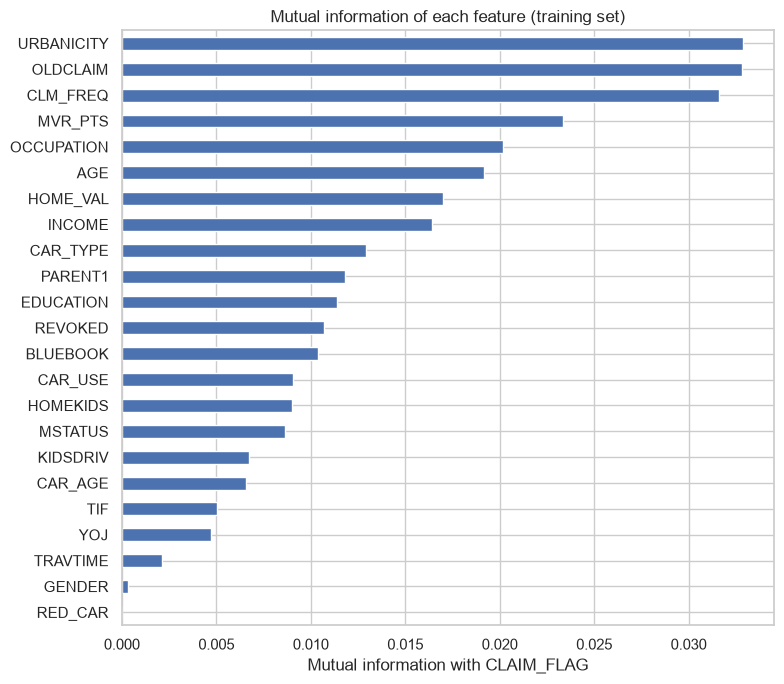

URBANICITY    0.0329
OLDCLAIM      0.0328
CLM_FREQ      0.0316
MVR_PTS       0.0234
OCCUPATION    0.0202
AGE           0.0192
HOME_VAL      0.0170
INCOME        0.0164
CAR_TYPE      0.0129
PARENT1       0.0118
EDUCATION     0.0114
REVOKED       0.0107
BLUEBOOK      0.0104
CAR_USE       0.0091
HOMEKIDS      0.0090
MSTATUS       0.0086
KIDSDRIV      0.0067
CAR_AGE       0.0066
TIF           0.0050
YOJ           0.0047
TRAVTIME      0.0021
GENDER        0.0003
RED_CAR       0.0000
dtype: float64

In [35]:
# which original feature each preprocessed column belongs to (nom__OCCUPATION_Doctor -> OCCUPATION)
column_feature = []
for col in X_train_prep.columns:
    name = col.split("__")[1]
    for feature in ALL_FEATURES:
        if name == feature or name.startswith(feature + "_"):
            column_feature.append(feature)
            break

continuous_cols = ["num__INCOME", "num__HOME_VAL", "num__BLUEBOOK", "num__OLDCLAIM", "num__TRAVTIME"]
discrete = [col not in continuous_cols for col in X_train_prep.columns]

mi = mutual_info_classif(X_train_prep, y_train, discrete_features=discrete, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=X_train_prep.columns)
mi_by_feature = mi.groupby(column_feature).sum().sort_values()    # add up the one-hot columns

ax = mi_by_feature.plot.barh(figsize=(8, 7), color="#4C72B0")
ax.set_xlabel("Mutual information with CLAIM_FLAG")
ax.set_title("Mutual information of each feature (training set)")
plt.tight_layout()
fig = ax.get_figure()
plt.show()

with mlflow.start_run(run_name="feature selection - filter methods"):
    mlflow.set_tag("stage", "feature_selection")
    mlflow.log_param("variance_threshold", 0.01)
    mlflow.log_metric("columns_removed_by_variance", int((~vt.get_support()).sum()))
    mlflow.log_figure(fig, "feature_selection/mutual_information.png")
    mlflow.log_text(mi_by_feature.to_csv(), "feature_selection/mutual_information.csv")

mi_by_feature.sort_values(ascending=False).round(4)

**This figure shows** the mutual information between each feature and `CLAIM_FLAG` on the training set. **We use it** to find features that carry no information about claims.

**Interpretation:** the most informative features are `URBANICITY` (0.033), `OLDCLAIM` (0.033), `CLM_FREQ` (0.032), `MVR_PTS` (0.023) and `OCCUPATION` (0.020), the same risk factors found in the EDA. `GENDER` (0.0003) and `RED_CAR` (0.0000) carry almost no information, which matches the EDA claim rates (red cars 26.2% vs others 26.9%). Both are removed by the filter step below.

In [36]:
FILTER_FEATURES = [f for f in ALL_FEATURES if f not in ["RED_CAR", "GENDER"]]
print(len(FILTER_FEATURES), "features kept by the filter step")

21 features kept by the filter step


### 7.3 Sequential Forward Selection (SFS)
SFS starts with no features and, at every step, adds the feature that raises the 5-fold CV ROC-AUC the most, until all 23 features are in. It then keeps the subset size with the best score. Logistic Regression is used as the judge because it was the best simple baseline and it is fast.

`feature_groups` makes SFS add or remove a whole original feature at once, so the 9 `OCCUPATION` columns always stay together.

SFS best subset: 17 features, CV ROC-AUC = 0.8111
Dropped: ['AGE', 'HOMEKIDS', 'YOJ', 'CAR_AGE', 'GENDER', 'RED_CAR']


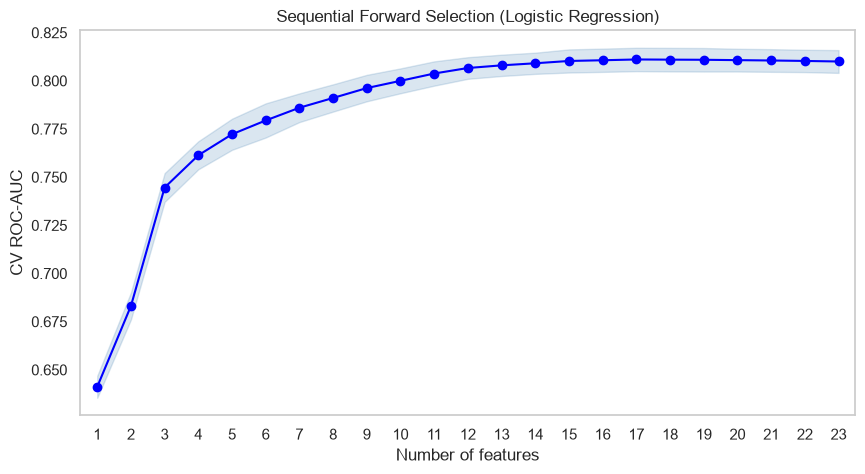

In [37]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs

# one group of column positions per original feature
feature_groups = []
for feature in ALL_FEATURES:
    group = [i for i, f in enumerate(column_feature) if f == feature]
    feature_groups.append(group)

lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

sfs = SFS(lr, k_features=(1, len(ALL_FEATURES)), forward=True, scoring="roc_auc",
          cv=cv, n_jobs=1, feature_groups=feature_groups)
sfs.fit(X_train_prep, y_train)

selected = set(column_feature[i] for i in sfs.k_feature_idx_)
SFS_FEATURES = [f for f in ALL_FEATURES if f in selected]
print("SFS best subset:", len(SFS_FEATURES), "features, CV ROC-AUC =", round(sfs.k_score_, 4))
print("Dropped:", [f for f in ALL_FEATURES if f not in SFS_FEATURES])

fig, ax = plot_sfs(sfs.get_metric_dict(), kind="std_err")
ax.set_xticks(range(1, len(ALL_FEATURES) + 1))
ax.set_xlim(0.5, len(ALL_FEATURES) + 0.5)
ax.set_title("Sequential Forward Selection (Logistic Regression)")
ax.set_xlabel("Number of features")
ax.set_ylabel("CV ROC-AUC")
plt.grid()
plt.show()

with mlflow.start_run(run_name="feature selection - SFS"):
    mlflow.set_tag("stage", "feature_selection")
    mlflow.log_params({"estimator": "LogisticRegression", "direction": "forward", "scoring": "roc_auc"})
    mlflow.log_metric("cv_roc_auc", sfs.k_score_)
    mlflow.log_metric("n_features", len(SFS_FEATURES))
    mlflow.log_figure(fig, "feature_selection/sfs.png")
    mlflow.log_text("\n".join(SFS_FEATURES), "feature_selection/sfs_features.txt")

**This figure shows** the best CV ROC-AUC found by SFS for every number of features, with the shaded band showing the standard error across the 5 folds. **We use it** to see how many features Logistic Regression really needs.

**Interpretation:** the score rises fast over the first 10 features (1 feature 0.641, 5 features 0.772, 10 features 0.800) and then flattens. The best subset has 17 features (0.8111), just above all 23 features (0.8100). SFS drops `AGE`, `HOMEKIDS`, `YOJ`, `CAR_AGE`, `GENDER` and `RED_CAR`.

### 7.4 Sequential Backward Selection (SBS)
SBS does the opposite: it starts with all 23 features and removes the least useful one at every step. Everything else is the same as SFS. If both directions end with the same subset, the result is reliable.

SBS best subset: 17 features, CV ROC-AUC = 0.8111
Dropped: ['AGE', 'HOMEKIDS', 'YOJ', 'CAR_AGE', 'GENDER', 'RED_CAR']
Same subset as SFS: True


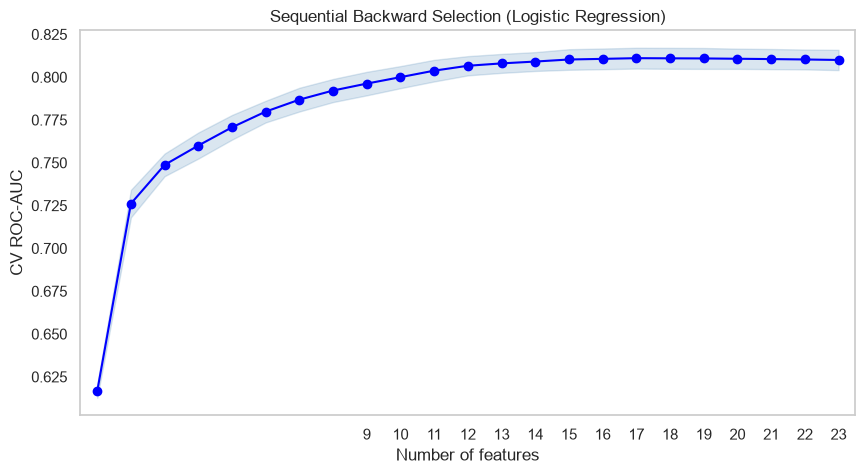

In [38]:
sbs = SFS(lr, k_features=(1, len(ALL_FEATURES)), forward=False, scoring="roc_auc",
          cv=cv, n_jobs=1, feature_groups=feature_groups)
sbs.fit(X_train_prep, y_train)

selected = set(column_feature[i] for i in sbs.k_feature_idx_)
SBS_FEATURES = [f for f in ALL_FEATURES if f in selected]
print("SBS best subset:", len(SBS_FEATURES), "features, CV ROC-AUC =", round(sbs.k_score_, 4))
print("Dropped:", [f for f in ALL_FEATURES if f not in SBS_FEATURES])
print("Same subset as SFS:", SBS_FEATURES == SFS_FEATURES)

fig, ax = plot_sfs(sbs.get_metric_dict(), kind="std_err")
ax.set_xticks(range(1, len(ALL_FEATURES) + 1))
ax.set_xlim(0.5, len(ALL_FEATURES) + 0.5)
ax.set_title("Sequential Backward Selection (Logistic Regression)")
ax.set_xlabel("Number of features")
ax.set_ylabel("CV ROC-AUC")
plt.grid()
plt.show()

with mlflow.start_run(run_name="feature selection - SBS"):
    mlflow.set_tag("stage", "feature_selection")
    mlflow.log_params({"estimator": "LogisticRegression", "direction": "backward", "scoring": "roc_auc"})
    mlflow.log_metric("cv_roc_auc", sbs.k_score_)
    mlflow.log_metric("n_features", len(SBS_FEATURES))
    mlflow.log_figure(fig, "feature_selection/sbs.png")
    mlflow.log_text("\n".join(SBS_FEATURES), "feature_selection/sbs_features.txt")

**This figure shows** the same curve for SBS, which starts with all 23 features and removes one at a time. **We use it** to check the SFS result from the opposite direction.

**Interpretation:** SBS ends with exactly the same 17 features and the same score (0.8111). Two searches in opposite directions agreeing is strong evidence that these 6 features are not needed for a linear model.

### 7.5 Comparing the feature sets on all models
SFS and SBS were judged by Logistic Regression only, so we now test the three feature sets (all 23, filter 21, SFS 17) on every model. Each test is a full pipeline inside 5-fold CV, so preprocessing is learned again in every fold. `preprocessor_for` makes a copy of the Section 5 preprocessor that only uses the chosen features.

In [39]:
from sklearn.base import clone

def preprocessor_for(features):
    # same preprocessing as Section 5, but only for the given features
    prep = clone(preprocessor)
    new_transformers = []
    for name, pipe, cols in prep.transformers:
        keep = [c for c in cols if c in features]
        new_transformers.append((name, pipe, keep))
    prep.transformers = new_transformers
    return prep

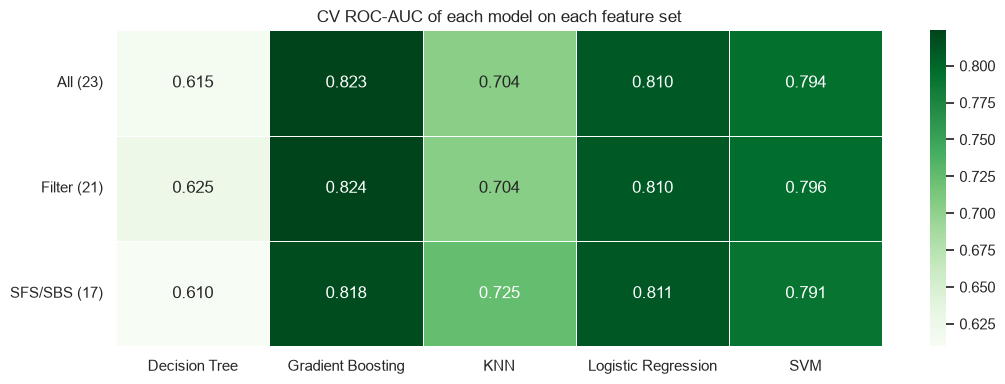

model,Decision Tree,Gradient Boosting,KNN,Logistic Regression,SVM
feature_set,,,,,
All (23),0.6151,0.8234,0.7039,0.8100,0.7943
Filter (21),0.6255,0.8239,0.7042,0.8104,0.7957
SFS/SBS (17),0.6096,0.8181,0.7250,0.8111,0.7912


In [40]:
feature_sets = {
    "All (23)": ALL_FEATURES,
    "Filter (21)": FILTER_FEATURES,
    "SFS/SBS (17)": SFS_FEATURES,
}

rows = []
for model_name, model in baseline_models.items():
    if model_name == "Dummy":
        continue
    for set_name, features in feature_sets.items():
        pipe = Pipeline([("prep", preprocessor_for(features)), ("model", model)])
        scores = cross_validate(pipe, X_train[features], y_train, cv=cv,
                                scoring=["roc_auc", "f1"], n_jobs=1)
        auc = scores["test_roc_auc"].mean()
        f1 = scores["test_f1"].mean()
        rows.append([model_name, set_name, auc, f1])

        with mlflow.start_run(run_name="feature set - " + model_name + " - " + set_name):
            mlflow.set_tag("stage", "feature_selection")
            mlflow.set_tag("model", model_name)
            mlflow.log_param("feature_set", set_name)
            mlflow.log_param("n_features", len(features))
            mlflow.log_metric("cv_roc_auc", auc)
            mlflow.log_metric("cv_f1", f1)

fs_df = pd.DataFrame(rows, columns=["model", "feature_set", "roc_auc", "f1"])
fs_auc = fs_df.pivot(index="feature_set", columns="model", values="roc_auc").loc[list(feature_sets)]

fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(fs_auc, annot=True, fmt=".3f", cmap="Greens", linewidths=0.5, ax=ax)
ax.set_title("CV ROC-AUC of each model on each feature set")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

with mlflow.start_run(run_name="feature selection - comparison"):
    mlflow.set_tag("stage", "feature_selection")
    mlflow.log_figure(fig, "feature_selection/feature_sets.png")
    mlflow.log_text(fs_df.to_csv(index=False), "feature_selection/feature_sets.csv")

fs_auc.round(4)

**This figure shows** the CV ROC-AUC of each model (columns) on each feature set (rows), with preprocessing learned again in every fold. **We use it** to choose which features each model will use.

**Interpretation:**
- The **filter set** (21 features, without `RED_CAR` and `GENDER`) is equal or better for every model, for example Decision Tree 0.615 to 0.625 and SVM 0.794 to 0.796.
- The **SFS/SBS set** (17 features) clearly helps only KNN (0.704 to 0.725), because irrelevant features add noise to its distance calculation. It slightly hurts the Decision Tree, SVM and Gradient Boosting (for example Gradient Boosting 0.823 to 0.818). SFS was judged by Logistic Regression, so it removed features like `AGE` and `YOJ` that a linear model cannot use but non-linear models can. The result of a wrapper method depends on the model used inside it.

### 7.6 Decision
- **All models** use `SELECTED_FEATURES`: the 21 features without `RED_CAR` and `GENDER`. The EDA, mutual information, SFS and SBS all agree that these two add nothing, and removing them never hurt any model.
- **KNN** uses `KNN_FEATURES`: the 17 SFS/SBS features, because it is the only model that clearly gains from the smaller set.

In [41]:
SELECTED_FEATURES = FILTER_FEATURES
KNN_FEATURES = SFS_FEATURES
print(len(SELECTED_FEATURES), "features for all models |", len(KNN_FEATURES), "features for KNN")

with mlflow.start_run(run_name="feature selection - decision"):
    mlflow.set_tag("stage", "feature_selection")
    mlflow.log_text("\n".join(SELECTED_FEATURES), "feature_selection/selected_features.txt")
    mlflow.log_text("\n".join(KNN_FEATURES), "feature_selection/knn_features.txt")

21 features for all models | 17 features for KNN


## 8. Hyperparameter Tuning
We tune each model with `GridSearchCV` : it tries every combination in a grid with the same 5-fold CV and keeps the one with the best ROC-AUC. Then it retrains that model on the whole training set. The test set is still not used.

For the models that support it, `class_weight="balanced"` is part of the grid. It makes a mistake on the rare claim class cost about 2.75 times more, which raises recall.

### 8.1 Validation curves
Before the grid search, we look at how one hyperparameter changes the training and validation ROC-AUC . A growing gap between the two curves means overfitting. Both curves low means underfitting.

Decision Tree: max_depth | best value: 5 | CV ROC-AUC: 0.749 | first: 0.637 | last: 0.628
Decision Tree: ccp_alpha (pruning) | best value: 0.001 | CV ROC-AUC: 0.756 | first: 0.625 | last: 0.653
KNN: n_neighbors | best value: 75 | CV ROC-AUC: 0.775 | first: 0.616 | last: 0.772
Logistic Regression: C | best value: 10 | CV ROC-AUC: 0.81 | first: 0.735 | last: 0.81


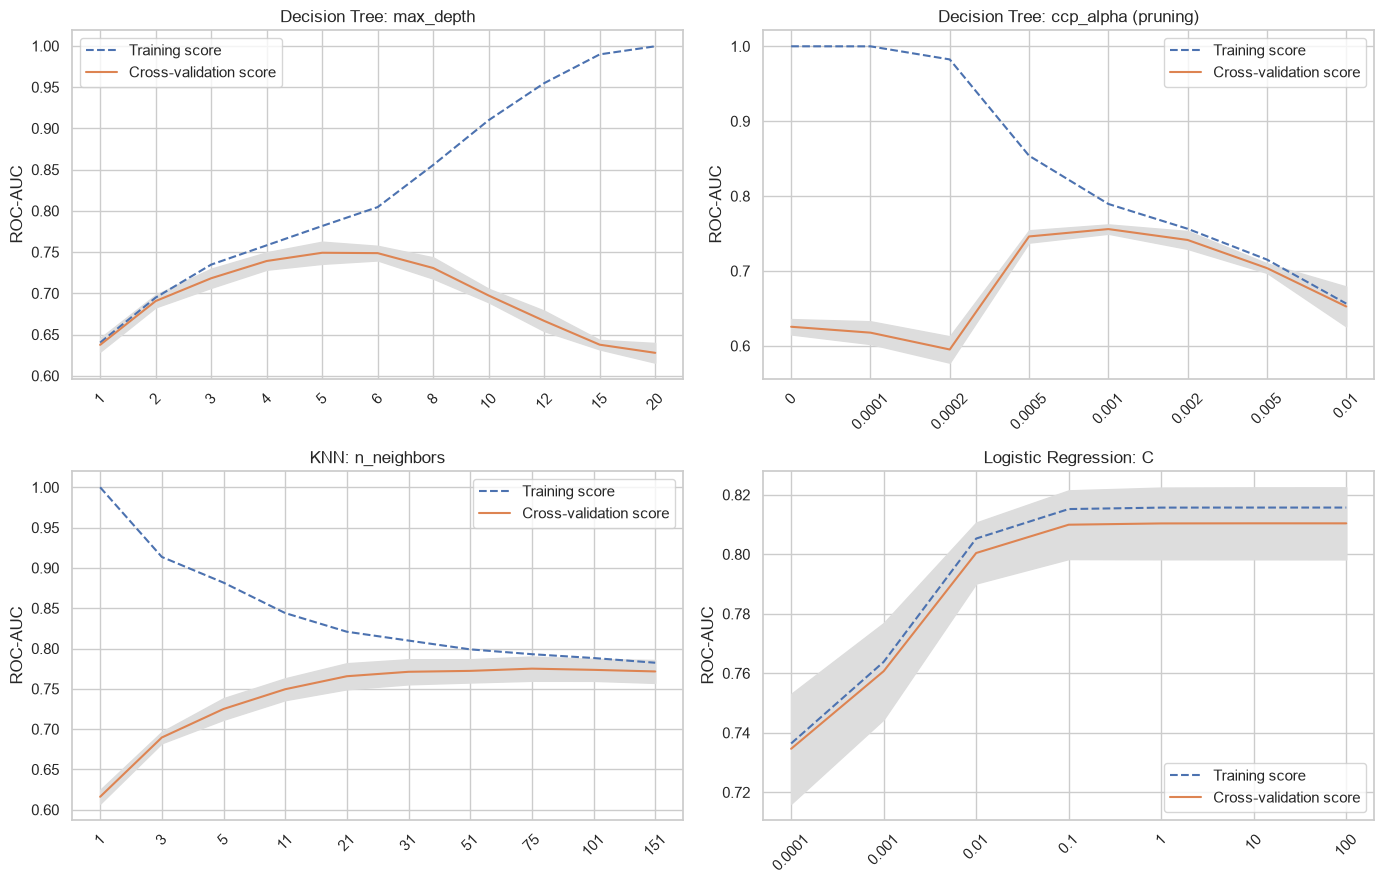

In [42]:
from sklearn.model_selection import validation_curve

curves = [
    ("Decision Tree: max_depth", DecisionTreeClassifier(random_state=RANDOM_STATE), SELECTED_FEATURES,
     "model__max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]),
    ("Decision Tree: ccp_alpha (pruning)", DecisionTreeClassifier(random_state=RANDOM_STATE), SELECTED_FEATURES,
     "model__ccp_alpha", [0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.01]),
    ("KNN: n_neighbors", KNeighborsClassifier(), KNN_FEATURES,
     "model__n_neighbors", [1, 3, 5, 11, 21, 31, 51, 75, 101, 151]),
    ("Logistic Regression: C", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), SELECTED_FEATURES,
     "model__C", [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for ax, (title, model, features, param, values) in zip(axes, curves):
    pipe = Pipeline([("prep", preprocessor_for(features)), ("model", model)])
    train_scores, val_scores = validation_curve(pipe, X_train[features], y_train, param_name=param,
                                                param_range=values, cv=cv, scoring="roc_auc", n_jobs=1)
    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    x = [str(v) for v in values]          # evenly spaced labels on the x-axis
    ax.plot(x, train_mean, "--", label="Training score")
    ax.plot(x, val_mean, label="Cross-validation score")
    ax.fill_between(x, val_mean - val_std, val_mean + val_std, color="#DDDDDD")
    ax.set_title(title)
    ax.set_ylabel("ROC-AUC")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    best = val_mean.argmax()
    print(title, "| best value:", values[best], "| CV ROC-AUC:", round(val_mean[best], 3),
          "| first:", round(val_mean[0], 3), "| last:", round(val_mean[-1], 3))

plt.tight_layout()
plt.show()

with mlflow.start_run(run_name="tuning - validation curves"):
    mlflow.set_tag("stage", "tuning")
    mlflow.log_figure(fig, "tuning/validation_curves.png")

**This figure shows** the training and validation ROC-AUC while one hyperparameter changes, for 4 key hyperparameters. **We use it** to see where each model starts to overfit or underfit, and to choose sensible values for the grid search.

**Interpretation:**
- **Decision Tree depth:** validation peaks at 0.749 at depth 5, then falls to 0.628 at depth 20 while training reaches 1.00. Deep trees memorise the data.
- **Pruning (`ccp_alpha`):** the unpruned tree scores 0.625, moderate pruning (0.001) raises it to 0.756, and too much pruning (0.01) drops it to 0.653 (underfitting).
- **KNN:** k = 1 memorises the data (training 1.00, validation 0.616). A larger k smooths the boundary, and validation levels off around k = 75 (0.775).
- **Logistic Regression:** training and validation stay close for every C, so it never overfits. Only very strong regularisation underfits (0.735 at C = 0.0001). From C = 0.1 it is stable at 0.810.

### 8.2 Grid search
| Model | Hyperparameters tuned | Why |
|---|---|---|
| Logistic Regression | C, `l1_ratio` (0 = L2, 1 = L1), class_weight | regularisation strength and type |
| Decision Tree | max_depth, min_samples_leaf, ccp_alpha, class_weight | limit growth and prune the tree to stop overfitting (Lab 2) |
| KNN | n_neighbors, weights | how smooth the decision boundary is |
| SVM | C, gamma, class_weight | how soft the margin is and how much the boundary bends |
| Gradient Boosting | n_estimators, learning_rate, max_depth | number and size of the boosting steps |

Since scikit-learn 1.8, Logistic Regression uses `l1_ratio` instead of `penalty`. The `saga` solver supports both L1 and L2.

Each model gets one MLflow run with its best parameters and CV scores, and every combination it tried is logged as a nested run inside it.

In [43]:
from sklearn.model_selection import GridSearchCV

CW = [None, "balanced"]

grids = {
    "Logistic Regression": (LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE),
                            SELECTED_FEATURES,
                            {"model__C": [0.01, 0.1, 1, 10],
                             "model__l1_ratio": [0, 1],
                             "model__class_weight": CW}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      SELECTED_FEATURES,
                      {"model__max_depth": [4, 6, 8, 10],
                       "model__min_samples_leaf": [25, 50, 100],
                       "model__ccp_alpha": [0, 0.0005, 0.001],
                       "model__class_weight": CW}),
    "KNN": (KNeighborsClassifier(),
            KNN_FEATURES,
            {"model__n_neighbors": [11, 31, 51, 75, 101],
             "model__weights": ["uniform", "distance"]}),
    "SVM": (SVC(random_state=RANDOM_STATE),
            SELECTED_FEATURES,
            {"model__C": [1, 10],
             "model__gamma": [0.01, 0.001],
             "model__class_weight": CW}),
    "Gradient Boosting": (GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE),
                          SELECTED_FEATURES,
                          {"model__n_estimators": [100, 300],
                           "model__learning_rate": [0.05, 0.1],
                           "model__max_depth": [2, 3]}),
}

MODEL_FEATURES = {}     # which features each model uses
for name, (model, features, grid) in grids.items():
    MODEL_FEATURES[name] = features

In [44]:
searches = {}
tuned_results = {}

for name, (model, features, grid) in grids.items():
    pipe = Pipeline([("prep", preprocessor_for(features)), ("model", model)])
    search = GridSearchCV(pipe, grid, scoring=SCORING, refit="roc_auc", cv=cv,
                          return_train_score=True, n_jobs=1)
    search.fit(X_train[features], y_train)
    searches[name] = search

    results = search.cv_results_
    best = search.best_index_
    tuned = {}
    for metric in SCORING:
        tuned[metric] = results["mean_test_" + metric][best]
    tuned["train_f1"] = results["mean_train_f1"][best]
    tuned_results[name] = tuned

    best_params = {}
    for key, value in search.best_params_.items():
        best_params[key.replace("model__", "")] = value

    with mlflow.start_run(run_name="tuning - " + name):
        mlflow.set_tag("stage", "tuning")
        mlflow.set_tag("model", name)
        mlflow.log_params(best_params)
        for metric, value in tuned.items():
            mlflow.log_metric("cv_" + metric, value)
        # every combination tried, as a nested run
        for j, params in enumerate(results["params"]):
            with mlflow.start_run(run_name=name + " - trial " + str(j), nested=True):
                for key, value in params.items():
                    mlflow.log_param(key.replace("model__", ""), value)
                for metric in SCORING:
                    mlflow.log_metric("cv_" + metric, results["mean_test_" + metric][j])

    print(name, "| ROC-AUC:", round(tuned["roc_auc"], 4), "| best:", best_params)

tuned_df = pd.DataFrame(tuned_results).T.sort_values("roc_auc", ascending=False).round(4)
tuned_df

Logistic Regression | ROC-AUC: 0.8105 | best: {'C': 1, 'class_weight': None, 'l1_ratio': 1}
Decision Tree | ROC-AUC: 0.771 | best: {'ccp_alpha': 0.0005, 'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 50}
KNN | ROC-AUC: 0.777 | best: {'n_neighbors': 75, 'weights': 'distance'}
SVM | ROC-AUC: 0.8165 | best: {'C': 1, 'class_weight': 'balanced', 'gamma': 0.01}
Gradient Boosting | ROC-AUC: 0.826 | best: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}


,accuracy,precision,recall,f1,roc_auc,train_f1
Gradient Boosting,0.7972,0.7015,0.4192,0.5240,0.8260,0.5630
SVM,0.7181,0.4830,0.7956,0.6010,0.8165,0.6103
Logistic Regression,0.7859,0.6548,0.4188,0.5106,0.8105,0.5164
KNN,0.7604,0.6799,0.1921,0.2987,0.7770,1.0000
Decision Tree,0.6870,0.4456,0.7023,0.5448,0.7710,0.6034


**Findings (best settings, 5-fold CV on the training set):**

| Model | ROC-AUC | F1 | Recall | Best settings |
|---|---|---|---|---|
| Gradient Boosting | 0.826 | 0.524 | 0.419 | 300 trees, depth 2, learning rate 0.05 |
| SVM | 0.817 | 0.601 | 0.796 | C = 1, gamma = 0.01, balanced |
| Logistic Regression | 0.811 | 0.511 | 0.419 | C = 1, L1 (`l1_ratio` = 1) |
| KNN | 0.777 | 0.299 | 0.192 | k = 75, distance weighted |
| Decision Tree | 0.771 | 0.545 | 0.702 | depth 10, at least 50 customers per leaf, ccp_alpha 0.0005, balanced |

The grid search picked simple settings everywhere: shallow trees for boosting, a large k for KNN and a pruned tree. SVM and the Decision Tree picked `class_weight="balanced"`, which is why their recall is high (0.796 and 0.702). Logistic Regression picked L1 regularisation (see 8.5).

### 8.3 Baseline vs tuned

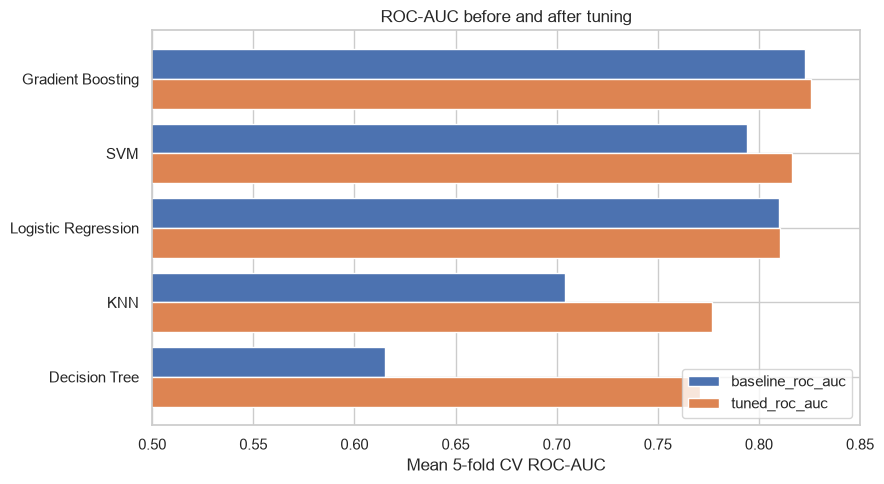

,baseline_roc_auc,tuned_roc_auc,gain
Gradient Boosting,0.823,0.8260,0.0030
SVM,0.794,0.8165,0.0225
Logistic Regression,0.810,0.8105,0.0005
KNN,0.704,0.7770,0.0730
Decision Tree,0.615,0.7710,0.1560


In [45]:
improvement = pd.DataFrame({
    "baseline_roc_auc": baseline_df["roc_auc"],
    "tuned_roc_auc": tuned_df["roc_auc"],
}).drop(index="Dummy")
improvement["gain"] = improvement["tuned_roc_auc"] - improvement["baseline_roc_auc"]
improvement = improvement.sort_values("tuned_roc_auc", ascending=False).round(4)

ax = improvement[["baseline_roc_auc", "tuned_roc_auc"]].plot.barh(figsize=(9, 5), width=0.8)
ax.invert_yaxis()
ax.set_xlim(0.5, 0.85)
ax.set_xlabel("Mean 5-fold CV ROC-AUC")
ax.set_title("ROC-AUC before and after tuning")
plt.tight_layout()
fig = ax.get_figure()
plt.show()

with mlflow.start_run(run_name="tuning - baseline vs tuned"):
    mlflow.set_tag("stage", "tuning")
    mlflow.log_figure(fig, "tuning/baseline_vs_tuned.png")
    mlflow.log_text(improvement.to_csv(), "tuning/baseline_vs_tuned.csv")

improvement

**This figure shows** each model's CV ROC-AUC with default settings (Section 6) and after tuning. **We use it** to measure what tuning gained.

**Interpretation:** the models that were overfitting gain the most: the Decision Tree +0.156 (0.615 to 0.771) thanks to depth limits and pruning, and KNN +0.073 thanks to a larger k. SVM gains +0.023. Logistic Regression (+0.001) and Gradient Boosting (+0.003) barely change, because their default settings were already good.

### 8.4 Overfitting after tuning

In [46]:
overfit_after = pd.DataFrame({
    "gap_before": overfit["gap"].drop("Dummy"),
    "train_f1_after": tuned_df["train_f1"],
    "validation_f1_after": tuned_df["f1"],
})
overfit_after["gap_after"] = overfit_after["train_f1_after"] - overfit_after["validation_f1_after"]
overfit_after.sort_values("gap_before", ascending=False).round(3)

,gap_before,train_f1_after,validation_f1_after,gap_after
Decision Tree,0.562,0.603,0.545,0.059
KNN,0.185,1.000,0.299,0.701
SVM,0.128,0.610,0.601,0.009
Gradient Boosting,0.073,0.563,0.524,0.039
Logistic Regression,0.007,0.516,0.511,0.006


**Findings:** tuning removed most of the overfitting: the Decision Tree gap fell from 0.562 to 0.059, SVM from 0.128 to 0.009 and Gradient Boosting from 0.073 to 0.039. KNN shows a training F1 of 1.000 because `weights="distance"` gives each training customer full weight on itself, so its training score is always perfect. This comes from how distance weighting works, not from overfitting, and its validation score did improve (8.3).

### 8.5 L1 regularisation (embedded feature selection)
The tuned Logistic Regression uses L1 regularisation (`l1_ratio=1`). L1 pushes the weights of useless columns to exactly 0, so the model selects features while it trains. The plot shows the learned weight of every column: red raises the chance of a claim, blue lowers it.

Columns removed by L1 (weight = 0): ['nom__OCCUPATION_Unknown', 'nom__CAR_TYPE_Panel Truck', 'nom__OCCUPATION_Home Maker']


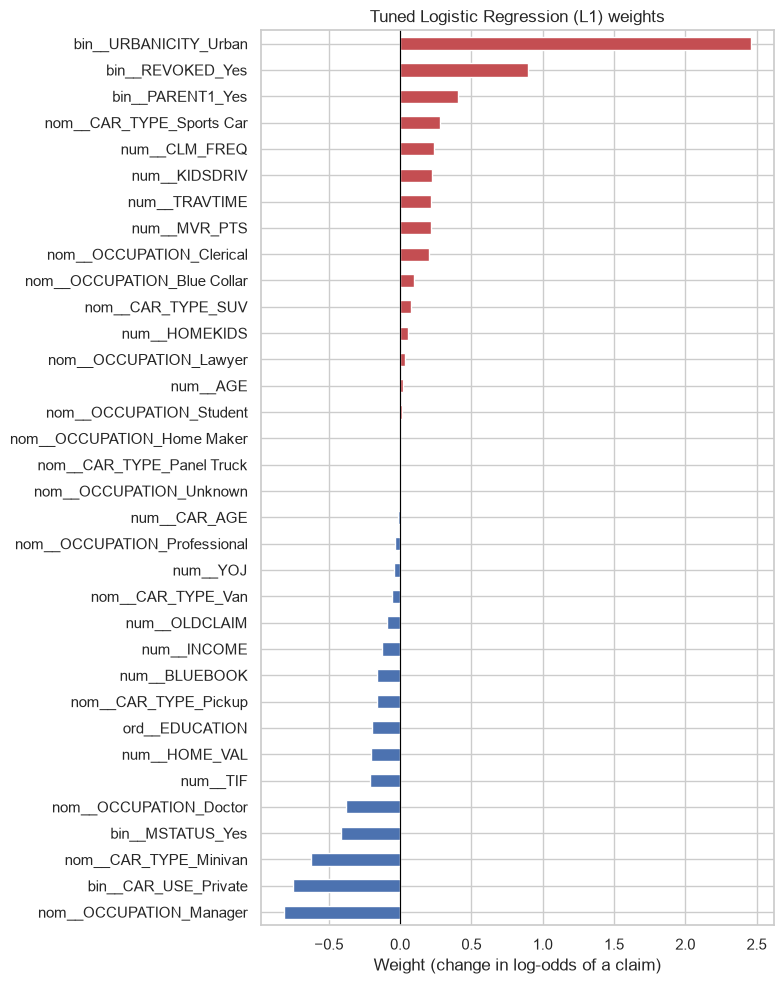

In [47]:
best_lr = searches["Logistic Regression"].best_estimator_
coefs = pd.Series(best_lr.named_steps["model"].coef_[0],
                  index=best_lr.named_steps["prep"].get_feature_names_out()).sort_values()

print("Columns removed by L1 (weight = 0):", list(coefs[coefs == 0].index))

colors = ["#C44E52" if c > 0 else "#4C72B0" for c in coefs]
ax = coefs.plot.barh(figsize=(8, 10), color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Weight (change in log-odds of a claim)")
ax.set_title("Tuned Logistic Regression (L1) weights")
plt.tight_layout()
fig = ax.get_figure()
plt.show()

with mlflow.start_run(run_name="tuning - L1 coefficients"):
    mlflow.set_tag("stage", "tuning")
    mlflow.set_tag("model", "Logistic Regression")
    mlflow.log_metric("n_zero_weights", int((coefs == 0).sum()))
    mlflow.log_figure(fig, "tuning/l1_coefficients.png")
    mlflow.log_text(coefs.to_csv(), "tuning/l1_coefficients.csv")

**This figure shows** the weight the tuned Logistic Regression gives each column. Red raises the chance of a claim and blue lowers it. Numeric weights are per 1 standard deviation. **We use it** as the embedded feature selection step and to see what drives the risk.

**Interpretation:**
- L1 set 3 columns to exactly 0 (`OCCUPATION_Home Maker`, `OCCUPATION_Unknown`, `CAR_TYPE_Panel Truck`), so the model removed them by itself.
- The biggest risk factors are urban living (+2.46), a revoked licence (+0.90), being a single parent (+0.41) and driving a sports car (+0.28). The biggest protective factors are being a manager (-0.81), private car use (-0.75), driving a minivan (-0.62) and being married (-0.42). This matches the EDA.
- `OLDCLAIM` gets a small negative weight even though past payouts go with more claims. It is almost a copy of `CLM_FREQ` (correlation 0.93), so the model gives their shared effect to `CLM_FREQ` (+0.23).

### 8.6 Decision threshold
A model predicts "claim" when its score is above a threshold (0.5 by default). In insurance a **false negative** (predicting no claim for a customer who then files one) is more costly than a false alarm, because that customer is under-priced. With only 27% claims, 0.5 is too strict and misses many claimants. `TunedThresholdClassifierCV` (built into scikit-learn) picks, for each tuned model, the threshold with the best F1 using CV on the training set only.

In [48]:
from sklearn.model_selection import TunedThresholdClassifierCV

final_models = {}
for name, search in searches.items():
    features = MODEL_FEATURES[name]
    model = TunedThresholdClassifierCV(search.best_estimator_, scoring="f1", cv=cv)
    model.fit(X_train[features], y_train)
    final_models[name] = model

    with mlflow.start_run(run_name="threshold - " + name):
        mlflow.set_tag("stage", "threshold")
        mlflow.log_param("threshold", model.best_threshold_)
        mlflow.log_metric("cv_f1_default_threshold", tuned_df.loc[name, "f1"])
        mlflow.log_metric("cv_f1_tuned_threshold", model.best_score_)

    print(name, "| threshold:", round(model.best_threshold_, 3),
          "| CV F1:", round(tuned_df.loc[name, "f1"], 3), "->", round(model.best_score_, 3))

Logistic Regression | threshold: 0.317 | CV F1: 0.511 -> 0.599
Decision Tree | threshold: 0.466 | CV F1: 0.545 -> 0.551
KNN | threshold: 0.228 | CV F1: 0.299 -> 0.563
SVM | threshold: 0.093 | CV F1: 0.601 -> 0.603
Gradient Boosting | threshold: 0.27 | CV F1: 0.524 -> 0.611


**Findings:** the chosen thresholds are below 0.5 (Logistic Regression 0.32, Gradient Boosting 0.27, KNN 0.23), so the models now flag more customers as risky. F1 rises most for the models trained without class weighting: KNN 0.299 to 0.563, Gradient Boosting 0.524 to 0.611 and Logistic Regression 0.511 to 0.599. SVM (0.601 to 0.603) and the Decision Tree (0.545 to 0.551) barely change because `class_weight="balanced"` had already moved their boundary. The SVM threshold (0.09) is on its decision score scale, not a probability.

## 9. Final Evaluation on the Test Set
The 2,061 test customers were not used for anything so far. Each tuned model (with its tuned threshold) now predicts them **once**, which gives an honest estimate of how it would do on new customers. The Dummy model is included as the reference.

### 9.1 Test results of all models

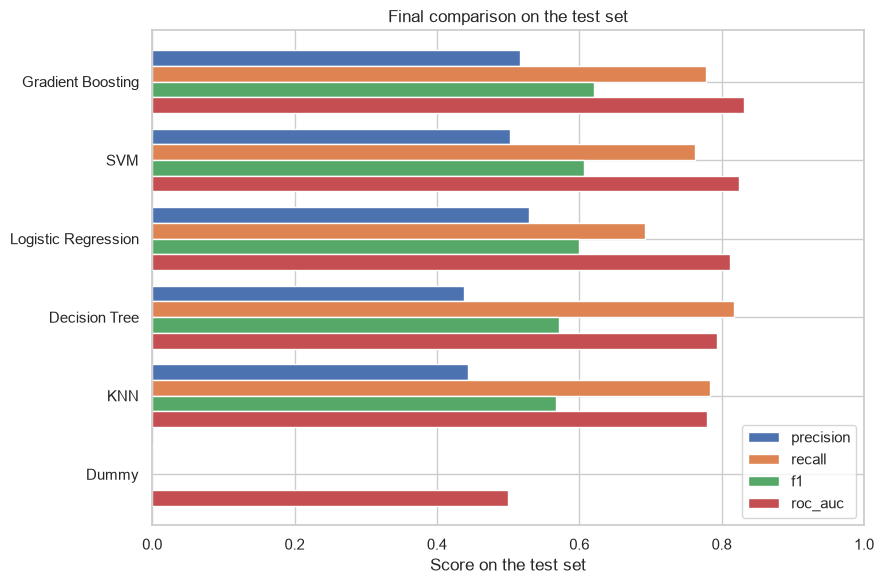

,accuracy,precision,recall,f1,roc_auc
Gradient Boosting,0.7467,0.5163,0.7778,0.6206,0.8315
SVM,0.7361,0.5030,0.7632,0.6064,0.8248
Logistic Regression,0.7545,0.5300,0.6922,0.6003,0.8115
Decision Tree,0.6725,0.4385,0.8179,0.5709,0.7929
KNN,0.6812,0.4442,0.7832,0.5669,0.7801
Dummy,0.7336,0.0000,0.0000,0.0000,0.5000


In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, get_scorer

roc_auc = get_scorer("roc_auc")   # uses predict_proba, or decision_function for the SVM

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
test_models = dict(final_models)
test_models["Dummy"] = dummy

test_results = {}
for name, model in test_models.items():
    features = MODEL_FEATURES.get(name, ALL_FEATURES)
    y_pred = model.predict(X_test[features])
    result = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc(model, X_test[features], y_test),
    }
    test_results[name] = result

    with mlflow.start_run(run_name="test - " + name):
        mlflow.set_tag("stage", "test")
        mlflow.set_tag("model", name)
        for metric, value in result.items():
            mlflow.log_metric("test_" + metric, value)

test_df = pd.DataFrame(test_results).T.sort_values("roc_auc", ascending=False).round(4)

ax = test_df[["precision", "recall", "f1", "roc_auc"]].plot.barh(figsize=(9, 6), width=0.8)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Score on the test set")
ax.set_title("Final comparison on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
fig = ax.get_figure()
plt.show()

with mlflow.start_run(run_name="test - comparison"):
    mlflow.set_tag("stage", "test")
    mlflow.log_figure(fig, "test/test_scores.png")
    mlflow.log_text(test_df.to_csv(), "test/test_results.csv")

test_df

**This figure shows** the precision, recall, F1 and ROC-AUC of every tuned model on the unseen test set, with the Dummy as the reference. **We use it** for the final comparison.

**Interpretation:**
- **Gradient Boosting is the best model:** ROC-AUC 0.832, F1 0.621, and it catches 78% of the claimants (recall 0.778). SVM is close (0.825, F1 0.606), then Logistic Regression (0.812, F1 0.600).
- Every model beats the Dummy (ROC-AUC 0.5, F1 0). The Dummy's accuracy (73.4%) is higher than that of the Decision Tree (67.3%) and KNN (68.1%) and only slightly below SVM (73.6%), even though it never catches a claim, which again shows that accuracy is the wrong metric here.
- The test scores are close to (and mostly a bit above) the CV scores, for example Gradient Boosting 0.826 in CV and 0.832 on the test set. The models generalise well.

### 9.2 Confusion matrices
Rows are the true class and columns the predicted class. The diagonal holds the correct predictions.

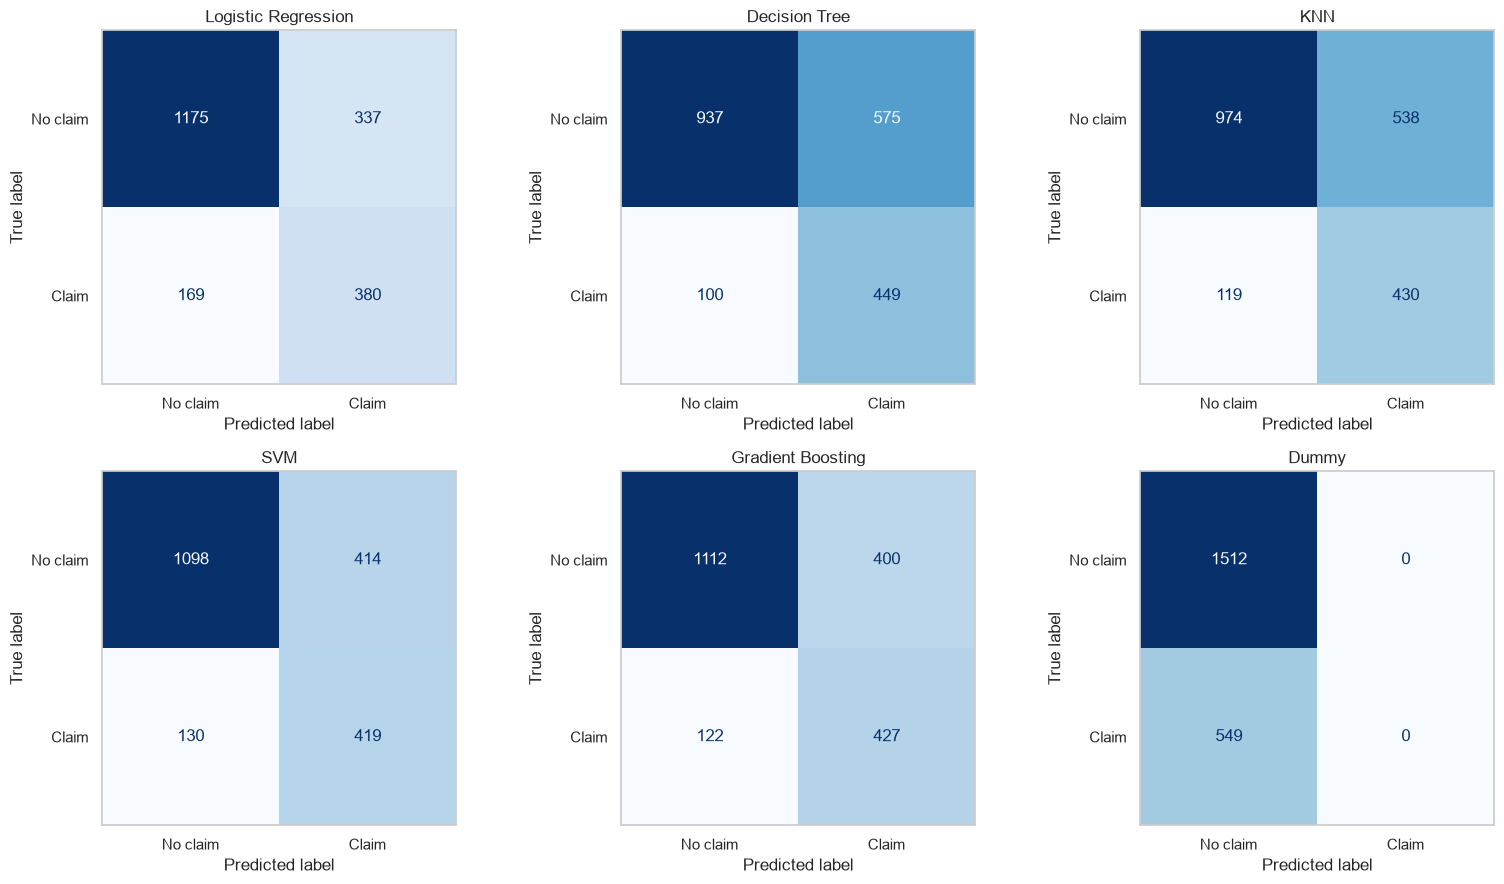

,true_neg,false_pos,false_neg (missed claims),true_pos (caught claims)
Logistic Regression,1175,337,169,380
Decision Tree,937,575,100,449
KNN,974,538,119,430
SVM,1098,414,130,419
Gradient Boosting,1112,400,122,427
Dummy,1512,0,549,0


In [50]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
counts = {}
for ax, name in zip(axes.ravel(), test_models):
    features = MODEL_FEATURES.get(name, ALL_FEATURES)
    y_pred = test_models[name].predict(X_test[features])
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No claim", "Claim"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    counts[name] = {"true_neg": tn, "false_pos": fp, "false_neg (missed claims)": fn, "true_pos (caught claims)": tp}
plt.tight_layout()
plt.show()

with mlflow.start_run(run_name="test - confusion matrices"):
    mlflow.set_tag("stage", "test")
    mlflow.log_figure(fig, "test/confusion_matrices.png")

pd.DataFrame(counts).T

**This figure shows** the confusion matrix of each model on the 2,061 test customers (1,512 no claim, 549 claim), and the table lists the same counts. **We use it** to count each type of mistake.

**Interpretation:**
- **Gradient Boosting** catches 427 of the 549 claimants and misses 122, with 400 false alarms.
- **SVM** catches 419 (misses 130) with 414 false alarms, and **Logistic Regression** catches 380 (misses 169) with 337 false alarms.
- The **Decision Tree** misses the fewest claimants (100) but raises the most false alarms (575).
- The **Dummy** never predicts a claim, so it misses all 549 claimants.

A missed claimant (false negative) is the costly mistake for an insurer, so Gradient Boosting gives the best balance: few missed claims for a moderate number of false alarms.

### 9.3 Classification reports
`classification_report` gives precision, recall and F1 for each class separately.

In [ ]:
from sklearn.metrics import classification_report

with mlflow.start_run(run_name="test - classification reports"):
    mlflow.set_tag("stage", "test")
    for name, model in final_models.items():
        features = MODEL_FEATURES[name]
        y_pred = model.predict(X_test[features])
        report = classification_report(y_test, y_pred, target_names=["No claim", "Claim"], digits=3)
        print("=====", name, "=====")
        print(report)
        # mlflow.log_text(report, "test/report_" + name.replace(" ", "_") + ".txt")

===== Logistic Regression =====
              precision    recall  f1-score   support

    No claim      0.874     0.777     0.823      1512
       Claim      0.530     0.692     0.600       549

    accuracy                          0.754      2061
   macro avg      0.702     0.735     0.712      2061
weighted avg      0.783     0.754     0.764      2061

===== Decision Tree =====
              precision    recall  f1-score   support

    No claim      0.904     0.620     0.735      1512
       Claim      0.438     0.818     0.571       549

    accuracy                          0.672      2061
   macro avg      0.671     0.719     0.653      2061
weighted avg      0.780     0.672     0.691      2061

===== KNN =====
              precision    recall  f1-score   support

    No claim      0.891     0.644     0.748      1512
       Claim      0.444     0.783     0.567       549

    accuracy                          0.681      2061
   macro avg      0.668     0.714     0.657      2061


**Findings:** every model does well on the "No claim" class (precision 0.87 to 0.90) because it is the majority class. The difficulty is the "Claim" class, where precision is only 0.44 to 0.53. Gradient Boosting has the best Claim F1 (0.621) and the best macro average F1 (0.715). The lower thresholds trade some no-claim recall (0.62 to 0.78) for much higher claim recall (0.69 to 0.82), which is the goal.

### 9.4 ROC and precision-recall curves

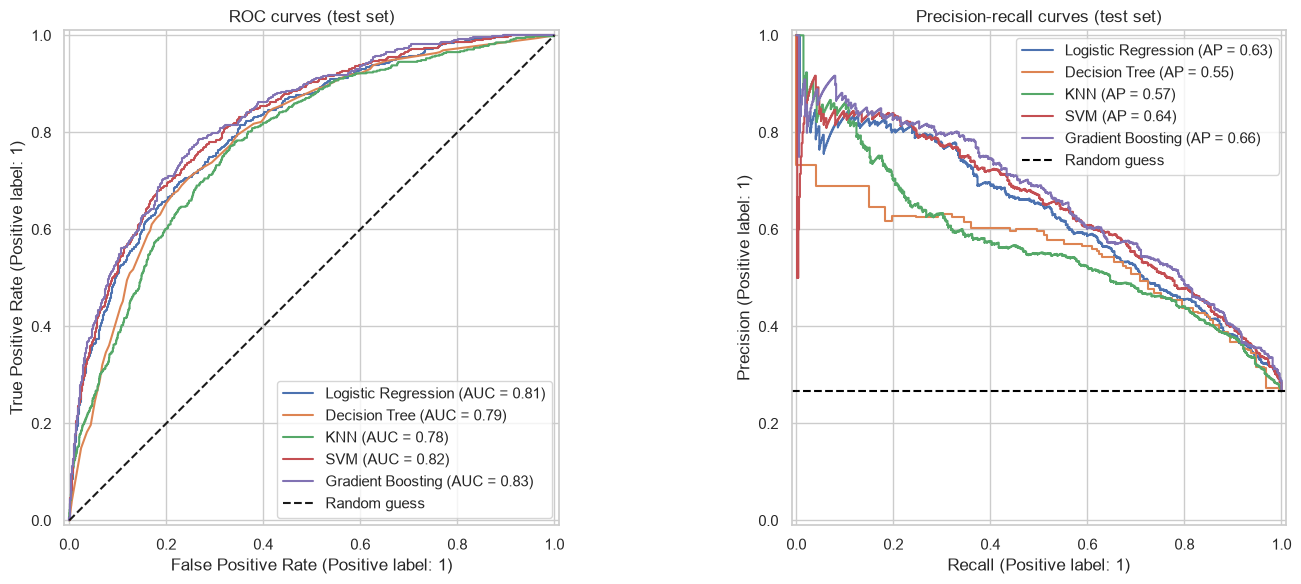

In [52]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, model in final_models.items():
    features = MODEL_FEATURES[name]
    RocCurveDisplay.from_estimator(model, X_test[features], y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(model, X_test[features], y_test, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].legend()
axes[1].axhline(y_test.mean(), color="black", linestyle="--", label="Random guess")
axes[1].legend()
axes[0].set_title("ROC curves (test set)")
axes[1].set_title("Precision-recall curves (test set)")
plt.tight_layout()
plt.show()

with mlflow.start_run(run_name="test - ROC and PR curves"):
    mlflow.set_tag("stage", "test")
    mlflow.log_figure(fig, "test/roc_pr_curves.png")

**This figure shows** the ROC curve (left) and the precision-recall curve (right) of each model on the test set, with a random guess as the dashed line. **We use it** to compare the models over all possible thresholds, not only the chosen one.

**Interpretation:** all curves are far above the random guess. Gradient Boosting is on top in both plots (AUC 0.83, average precision 0.66), with SVM and Logistic Regression close behind. KNN and the Decision Tree are clearly lower. The precision-recall curves show the trade-off: catching more claimants always costs more false alarms.

### 9.5 Final model
**Gradient Boosting** is the final model. It had the best CV ROC-AUC during tuning (0.826), and the test set confirms it: best ROC-AUC (0.832), best F1 (0.621) and 78% of the claims caught. It does not overfit (training/validation gap 0.039).
- **Logistic Regression** is the better choice if the insurer must explain every decision: it is only 0.02 ROC-AUC lower and its weights are easy to read (8.5).
- **Limitation:** even the best model misses 22% of the claimants and flags 26% of the non-claimants. Whether a customer claims also depends on chance (an accident on a given day), which no feature can capture.

The final model (preprocessing + Gradient Boosting + tuned threshold) is saved in MLflow so it can be loaded later to score new customers.

In [53]:
import mlflow.sklearn

best_name = "Gradient Boosting"
best_model = final_models[best_name]

with mlflow.start_run(run_name="final model - " + best_name):
    mlflow.set_tag("stage", "final_model")
    mlflow.set_tag("model", best_name)
    for key, value in searches[best_name].best_params_.items():
        mlflow.log_param(key.replace("model__", ""), value)
    mlflow.log_param("threshold", best_model.best_threshold_)
    for metric, value in test_results[best_name].items():
        mlflow.log_metric("test_" + metric, value)
    # cloudpickle is needed because MLflow's default format cannot save the threshold wrapper
    mlflow.sklearn.log_model(best_model, name="final_model", serialization_format="cloudpickle")

print("Final model saved to MLflow:", best_name)

2026/11/11 06:56:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Final model saved to MLflow: Gradient Boosting


## 10. Learning Curves and Bias-Variance
A learning curve shows the training and validation score as the model gets more training data (Lab 5). If both curves meet and stay flat, the model is limited by its simplicity (bias) and more data will not help. If there is a big gap, the model overfits (variance). If the validation curve is still rising, more data would help.

### 10.1 Learning curves

Logistic Regression | validation ROC-AUC: [0.803, 0.807, 0.81, 0.81, 0.81] | final gap: 0.005
Decision Tree | validation ROC-AUC: [0.739, 0.755, 0.765, 0.763, 0.771] | final gap: 0.045
KNN | validation ROC-AUC: [0.758, 0.765, 0.77, 0.773, 0.777] | final gap: 0.223
SVM | validation ROC-AUC: [0.799, 0.808, 0.813, 0.815, 0.816] | final gap: 0.016
Gradient Boosting | validation ROC-AUC: [0.808, 0.82, 0.821, 0.825, 0.826] | final gap: 0.025


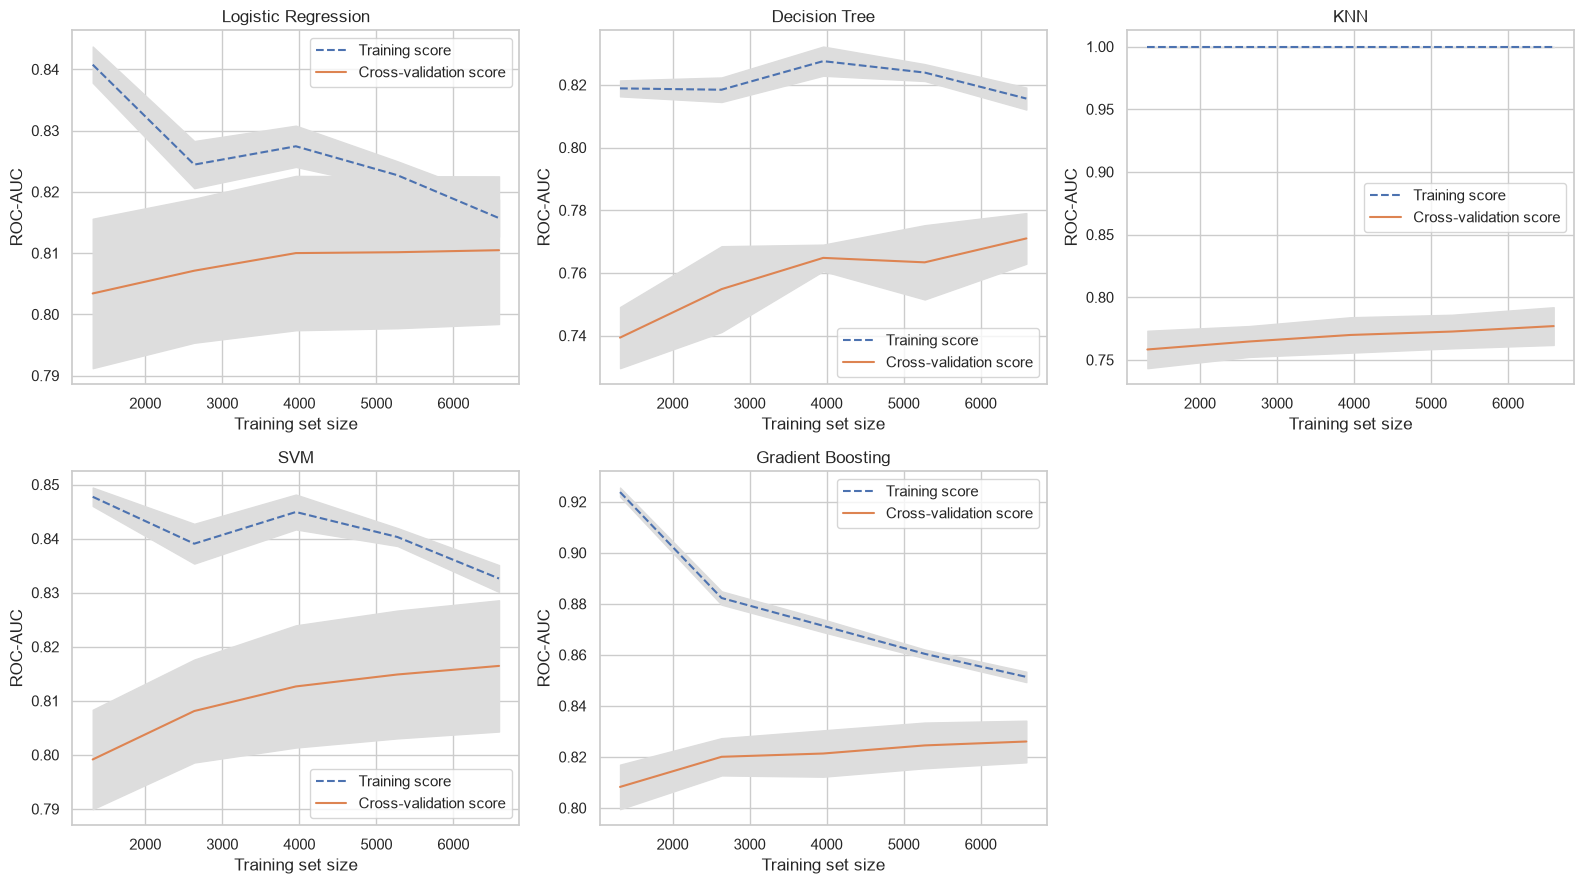

In [54]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for ax, name in zip(axes, searches):
    features = MODEL_FEATURES[name]
    sizes, train_scores, val_scores = learning_curve(searches[name].best_estimator_, X_train[features], y_train,
                                                     cv=cv, scoring="roc_auc", n_jobs=1,
                                                     train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0])
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    ax.plot(sizes, train_mean, "--", label="Training score")
    ax.plot(sizes, val_mean, label="Cross-validation score")
    ax.fill_between(sizes, train_mean - train_std, train_mean + train_std, color="#DDDDDD")
    ax.fill_between(sizes, val_mean - val_std, val_mean + val_std, color="#DDDDDD")
    ax.set_title(name)
    ax.set_xlabel("Training set size")
    ax.set_ylabel("ROC-AUC")
    ax.legend(loc="best")
    print(name, "| validation ROC-AUC:", [round(float(v), 3) for v in val_mean],
          "| final gap:", round(train_mean[-1] - val_mean[-1], 3))

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

with mlflow.start_run(run_name="learning curves"):
    mlflow.set_tag("stage", "learning_curves")
    mlflow.log_figure(fig, "learning_curves/learning_curves.png")

**This figure shows** the training and validation ROC-AUC of each tuned model as the training set grows from 20% to 100%. **We use it** to see whether each model is limited by bias or by variance, and whether more data would help.

**Interpretation:**
- **Logistic Regression:** the curves almost meet (gap 0.005) and validation is flat from about 4,000 customers (0.810). It is limited by bias, so more data will not help.
- **Decision Tree:** validation rises from 0.739 to 0.771 and is still rising (gap 0.045), so more data would still help a little.
- **KNN:** training is always 1.00 because of distance weighting, so the gap is not meaningful. Validation rises slowly (0.758 to 0.777).
- **SVM and Gradient Boosting:** small gaps (0.016 and 0.025) and validation still rising slightly (Gradient Boosting 0.808 to 0.826), so more data would give only a small gain.
- All validation curves flatten, so the ceiling of about 0.83 comes from the limited information in the features, not from too little data.

### 10.2 Bias-variance decomposition
`bias_variance_decomp` (mlxtend) trains each tuned model 20 times on random samples of the training set and predicts the test set each time. The average error is split into **bias** (error that stays even in the average prediction, the model is too simple) and **variance** (how much the predictions change between samples, the model is too sensitive to the data). It uses the 0.5 threshold, so the loss is close to 1 minus accuracy.

mlxtend passes plain NumPy arrays to the model, so the data is preprocessed first with each model's already fitted preprocessing step.

Logistic Regression | loss: 0.207 | bias: 0.205 | variance: 0.022
Decision Tree | loss: 0.310 | bias: 0.277 | variance: 0.176
KNN | loss: 0.239 | bias: 0.236 | variance: 0.037
SVM | loss: 0.281 | bias: 0.278 | variance: 0.040
Gradient Boosting | loss: 0.200 | bias: 0.197 | variance: 0.035


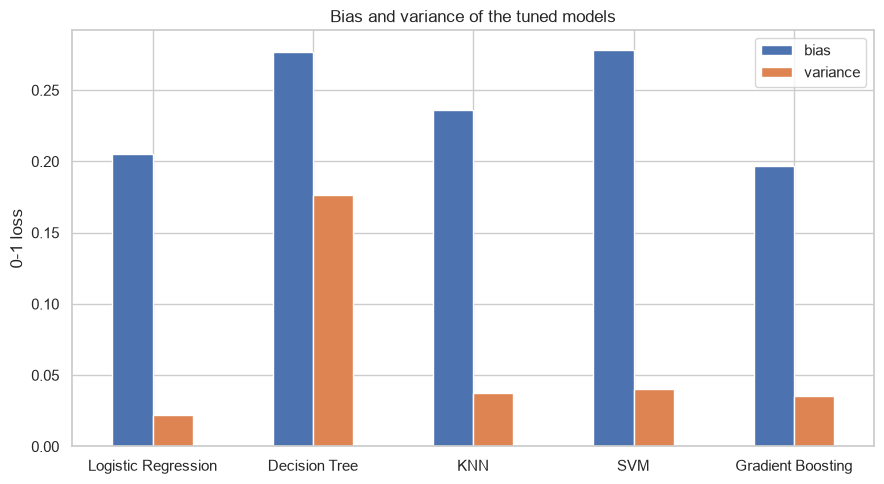

,loss,bias,variance
Logistic Regression,0.2071,0.2052,0.0218
Decision Tree,0.3099,0.2770,0.1765
KNN,0.2393,0.2363,0.0372
SVM,0.2811,0.2780,0.0404
Gradient Boosting,0.1999,0.1965,0.0353


In [55]:
from mlxtend.evaluate import bias_variance_decomp

bv_results = {}
for name, search in searches.items():
    features = MODEL_FEATURES[name]
    prep = search.best_estimator_.named_steps["prep"]
    X_tr = prep.transform(X_train[features]).to_numpy()
    X_te = prep.transform(X_test[features]).to_numpy()
    model = clone(search.best_estimator_.named_steps["model"])    # untrained copy with the tuned settings

    loss, bias, var = bias_variance_decomp(model, X_tr, y_train.to_numpy(), X_te, y_test.to_numpy(),
                                           loss="0-1_loss", num_rounds=20, random_seed=RANDOM_STATE)
    bv_results[name] = {"loss": loss, "bias": bias, "variance": var}
    print(name, "| loss: %.3f | bias: %.3f | variance: %.3f" % (loss, bias, var))

bv_df = pd.DataFrame(bv_results).T.round(4)

ax = bv_df[["bias", "variance"]].plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("0-1 loss")
ax.set_title("Bias and variance of the tuned models")
plt.tight_layout()
fig = ax.get_figure()
plt.show()

with mlflow.start_run(run_name="bias-variance"):
    mlflow.set_tag("stage", "learning_curves")
    for name, values in bv_results.items():
        for key, value in values.items():
            mlflow.log_metric(name.replace(" ", "_") + "_" + key, value)
    mlflow.log_figure(fig, "learning_curves/bias_variance.png")

bv_df

**This figure shows** the bias and variance part of each tuned model's error on the test set (20 retrainings on random samples). **We use it** to put numbers on underfitting (bias) and overfitting (variance).

**Interpretation:**
- **Gradient Boosting** has the lowest total error (0.200) and the lowest bias (0.197), with low variance (0.035). Boosting lowers bias by adding many small trees, and the small learning rate keeps the variance low.
- **Logistic Regression** has the lowest variance (0.022): a linear model barely changes between samples. Its bias (0.205) is a bit higher.
- **The Decision Tree** has by far the highest variance (0.176), even after pruning: a single tree changes a lot when the data changes. This is exactly the weakness that ensembles like Gradient Boosting fix.
- **SVM and the Decision Tree** show higher bias here partly because they use `class_weight="balanced"`, which makes them predict "claim" more often at the 0.5 rule, and this loss counts every wrong prediction the same.

## Conclusion
- **Data:** 10,301 customers and 23 features after cleaning. The leakage column `CLM_AMT` was removed, currency and labels were fixed, and missing values were imputed inside the pipeline.
- **Feature selection:** `RED_CAR` and `GENDER` carry no information (EDA, mutual information, SFS and SBS agree) and were removed. KNN uses the 17 SFS/SBS features. L1 regularisation removed 3 more columns inside Logistic Regression.
- **Tuning:** GridSearchCV helped most where models overfitted (Decision Tree +0.156 ROC-AUC, KNN +0.073). A lower decision threshold raised recall because missing a claim is the costly mistake.
- **Best model:** Gradient Boosting, with test ROC-AUC 0.832, F1 0.621 and recall 0.778 (catches 427 of 549 claims).
- **Main risk drivers:** urban living, a revoked licence, single parenthood, past claims and traffic violation points.
- **Limit:** the models reach about 0.83 ROC-AUC, and the learning curves show that more data would add little. Going further would need more informative features rather than more customers.